In [4]:
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [6]:
#Quality Assessment (QA) band–based masking
import numpy as np

# Dummy QA band to demonstrate logic
qa = np.random.randint(0, 4096, (100, 100))  # QA60 is 16-bit

# Bit positions (Sentinel-2 QA60)
cloud_bit  = 1 << 10
cirrus_bit = 1 << 11

qa_mask = ((qa & cloud_bit) == 0) & ((qa & cirrus_bit) == 0)


In [7]:
#Cloud Probability Thresholding
# Simulated cloud probability (0–100%)
cloud_prob = np.random.randint(0, 100, (100, 100))

# Threshold (<10% = clear)
cloud_prob_mask = cloud_prob < 10


In [8]:
#Spectral Threshold Rule-Based Masking
#S2_PreFire.tif
#(or During / Post similarly)
import rasterio
import numpy as np

# Open Sentinel-2 image
with rasterio.open("Fire_Project/S2_PreFire.tif") as src:
    blue = src.read(1).astype(float)   # B2
    red  = src.read(2).astype(float)   # B4
    nir  = src.read(3).astype(float)   # B8



In [9]:
#Temporary NDVI (for cloud detection)
ndvi_temp = (nir - red) / (nir + red + 1e-6)
#Spectral Threshold Cloud Mask
spectral_cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)
#Apply Mask to Bands (IMPORTANT STEP)
red_masked = np.where(spectral_cloud_mask, red, np.nan)
nir_masked = np.where(spectral_cloud_mask, nir, np.nan)



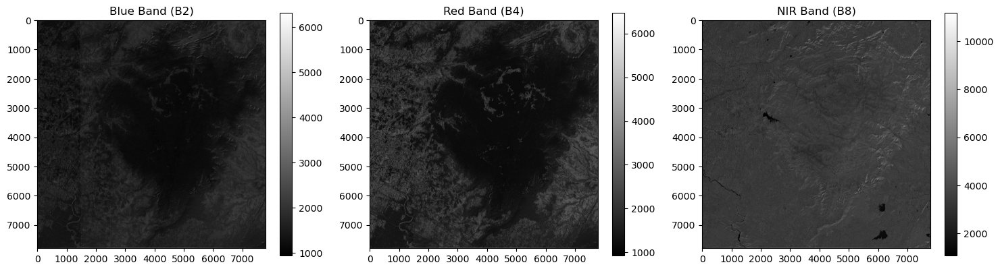

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.imshow(blue, cmap='gray')
plt.title("Blue Band (B2)")
plt.colorbar()

plt.subplot(1,3,2)
plt.imshow(red, cmap='gray')
plt.title("Red Band (B4)")
plt.colorbar()

plt.subplot(1,3,3)
plt.imshow(nir, cmap='gray')
plt.title("NIR Band (B8)")
plt.colorbar()

plt.tight_layout()
plt.show()


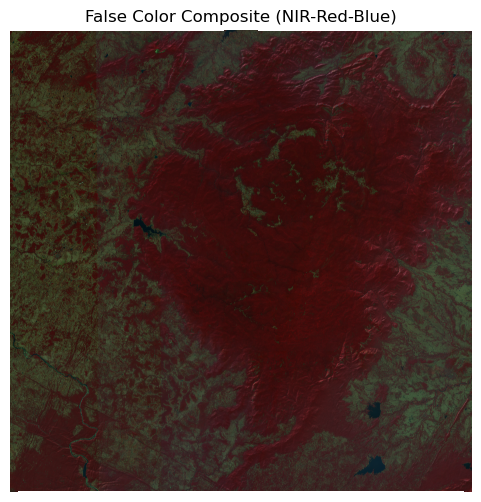

In [11]:
#DISPLAY TRUE COLOR / FALSE COLOR COMPOSITE (VERY IMPORTANT)
# Normalize bands for display
def normalize(band):
    return (band - np.nanmin(band)) / (np.nanmax(band) - np.nanmin(band))

fcc = np.dstack((
    normalize(nir),   # R channel
    normalize(red),   # G channel
    normalize(blue)   # B channel
))

plt.figure(figsize=(6,6))
plt.imshow(fcc)
plt.title("False Color Composite (NIR-Red-Blue)")
plt.axis('off')
plt.show()


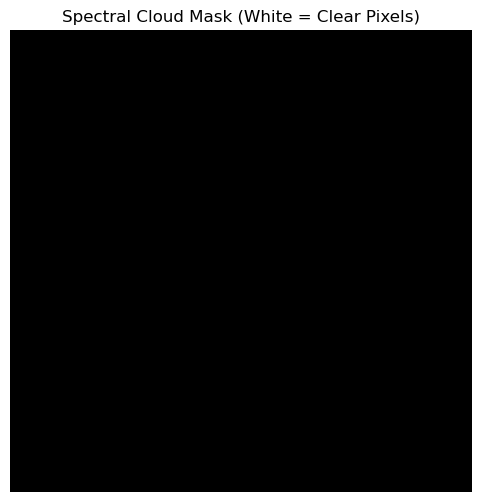

In [ ]:
#DISPLAY SPECTRAL CLOUD MASK RESULT
# Temporary NDVI for cloud detection
ndvi_temp = (nir - red) / (nir + red + 1e-6)

spectral_cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)

plt.figure(figsize=(6,6))
plt.imshow(spectral_cloud_mask, cmap='gray')
plt.title("Spectral Cloud Mask (White = Clear Pixels)")
plt.axis('off')
plt.show()


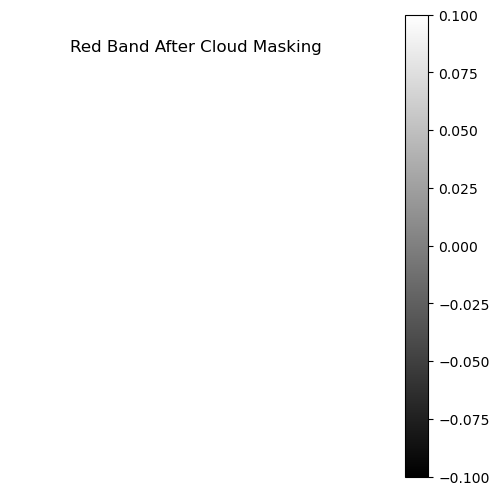

In [13]:
#APPLY MASK AND SHOW CLEANED IMAGE
red_masked = np.where(spectral_cloud_mask, red, np.nan)

plt.figure(figsize=(6,6))
plt.imshow(red_masked, cmap='gray')
plt.title("Red Band After Cloud Masking")
plt.colorbar()
plt.axis('off')
plt.show()


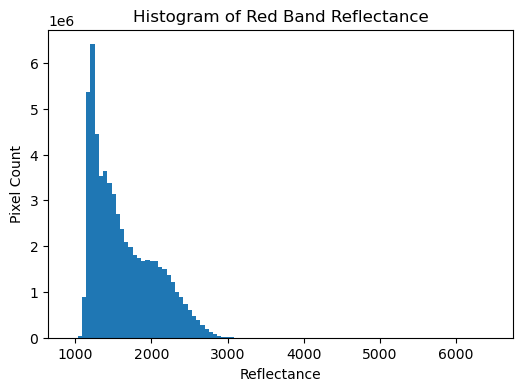

In [14]:
plt.figure(figsize=(6,4))
plt.hist(red[~np.isnan(red)].flatten(), bins=100)
plt.title("Histogram of Red Band Reflectance")
plt.xlabel("Reflectance")
plt.ylabel("Pixel Count")
plt.show()


Pre- processing

1.⁠ ⁠Cloud Masking

In [28]:
import rasterio
import numpy as np

def cloud_mask_and_extract(path):
    with rasterio.open(path) as src:
        blue = src.read(1).astype(float)   # B2
        red  = src.read(2).astype(float)   # B4
        nir  = src.read(3).astype(float)   # B8
        swir = src.read(4).astype(float)   # B11
        meta = src.meta

    # Temporary NDVI (for cloud detection)
    ndvi_temp = (nir - red) / (nir + red + 1e-6)

    # Spectral cloud mask
    spectral_cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)

    # Apply mask
    red_masked  = np.where(spectral_cloud_mask, red, np.nan)
    nir_masked  = np.where(spectral_cloud_mask, nir, np.nan)
    swir_masked = np.where(spectral_cloud_mask, swir, np.nan)

    return red_masked, nir_masked, swir_masked, meta


In [29]:
red_pre, nir_pre, swir_pre, meta = cloud_mask_and_extract(
    "Fire_Project/S2_PreFire.tif"
)


In [30]:
red_dur, nir_dur, swir_dur, _ = cloud_mask_and_extract(
    "Fire_Project/S2_DuringFire.tif"
)


In [31]:
red_post, nir_post, swir_post, _ = cloud_mask_and_extract(
    "Fire_Project/S2_PostFire.tif"
)


In [32]:
print("Red band shape:", red_dur.shape)
print("NIR band shape:", nir_dur.shape)
print("SWIR band shape:", swir_dur.shape)


Red band shape: (7798, 7793)
NIR band shape: (7798, 7793)
SWIR band shape: (7798, 7793)


In [33]:
blue, red, nir   # OR red_masked, nir_masked if masking applied


(array([[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [1418. , 1420. , 1420. , ..., 1608. , 1532. , 1562. ],
        [1466. , 1467. , 1467. , ..., 1562. , 1525. , 1606. ],
        [1489.5, 1463. , 1463. , ..., 1594. , 1567. , 1521. ]],
       shape=(7798, 7793)),
 array([[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [1633. , 1625. , 1625. , ..., 1512. , 1482. , 1496. ],
        [1701. , 1690.5, 1690.5, ..., 1530. , 1540. , 1518. ],
        [1726. , 1670. , 1670. , ..., 1561. , 1589. , 1571. ]],
       shape=(7798, 7793)),
 array([[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, .

In [35]:
s2_images = {
    "Pre-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    "During-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    "Post-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif"
}


In [ ]:
#Function to READ + MASK + DISPLAY
import rasterio
import numpy as np
import matplotlib.pyplot as plt

def normalize(band):
    return (band - np.nanmin(band)) / (np.nanmax(band) - np.nanmin(band))

def display_s2_outputs(title, path):
    with rasterio.open(path) as src:
        blue = src.read(1).astype(float)
        red  = src.read(2).astype(float)
        nir  = src.read(3).astype(float)

    # Temporary NDVI for cloud masking
    ndvi_temp = (nir - red) / (nir + red + 1e-6)
    spectral_cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)

    red_masked = np.where(spectral_cloud_mask, red, np.nan)
    nir_masked = np.where(spectral_cloud_mask, nir, np.nan)

    # ---------- DISPLAY ----------
    plt.figure(figsize=(16,4))

    plt.subplot(1,4,1)
    plt.imshow(blue, cmap='gray')
    plt.title(f"{title} - Blue")
    plt.axis('off')

    plt.subplot(1,4,2)
    plt.imshow(red, cmap='gray')
    plt.title(f"{title} - Red")
    plt.axis('off')

    plt.subplot(1,4,3)
    plt.imshow(nir, cmap='gray')
    plt.title(f"{title} - NIR")
    plt.axis('off')

    fcc = np.dstack((normalize(nir), normalize(red), normalize(blue)))
    plt.subplot(1,4,4)
    plt.imshow(fcc)
    plt.title(f"{title} - FCC")
    plt.axis('off')

    plt.show()

    # Cloud-masked output
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.imshow(red_masked, cmap='gray')
    plt.title(f"{title} - Red Masked")
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.imshow(nir_masked, cmap='gray')
    plt.title(f"{title} - NIR Masked")
    plt.axis('off')

    plt.show()


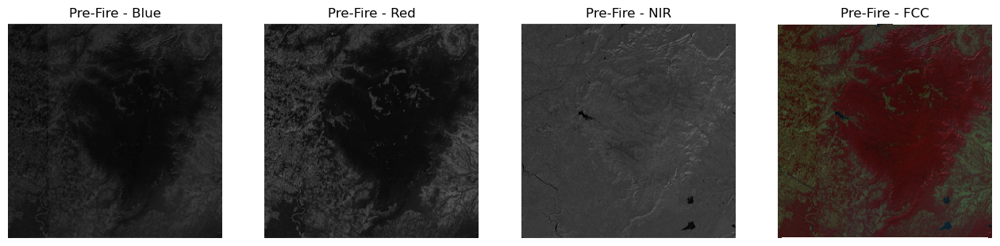

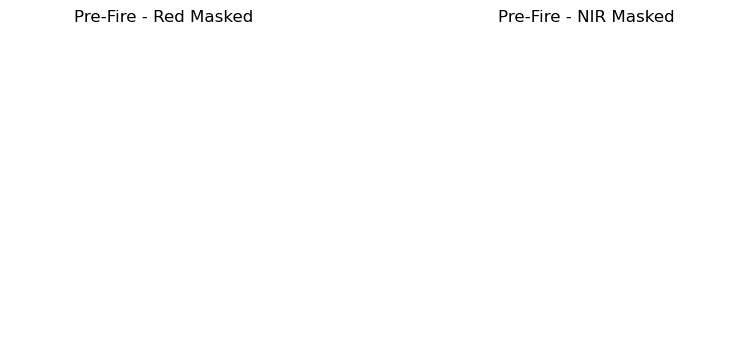

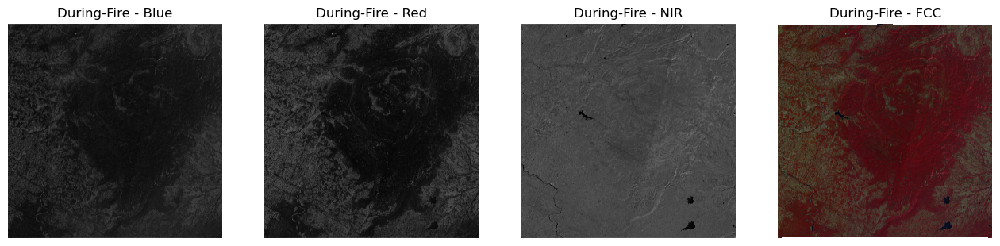

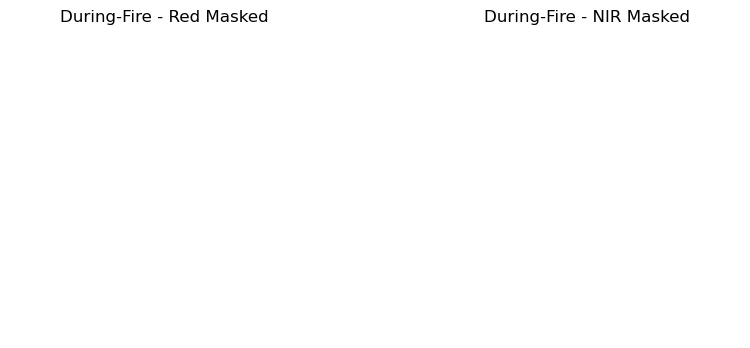

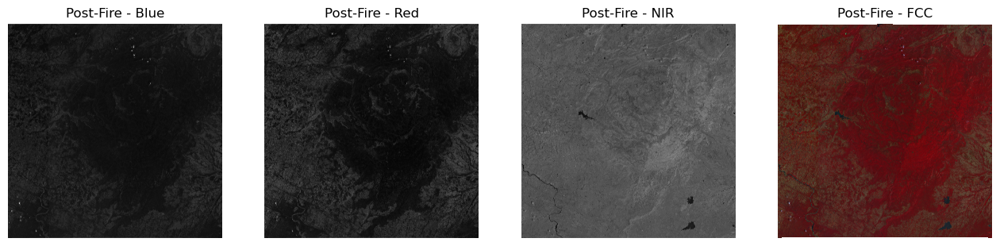

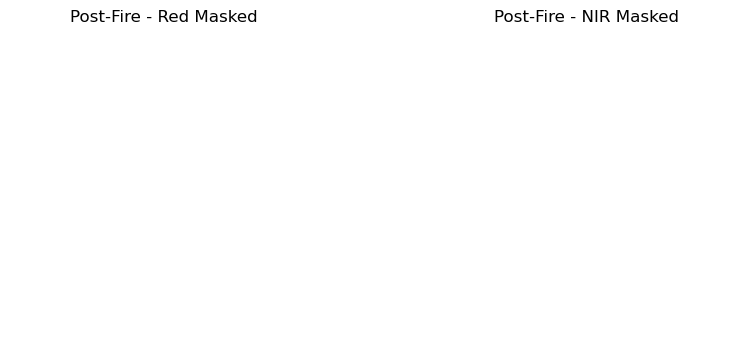

In [37]:
for phase, path in s2_images.items():
    display_s2_outputs(phase, path)


Pre- processing

2. ⁠Atmospheric Correction

In [ ]:
#DARK OBJECT SUBTRACTION (DOS)

In [38]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

def dark_object_subtraction(band):
    """
    Simple DOS correction:
    subtract minimum reflectance (1st percentile)
    """
    dark_object = np.nanpercentile(band, 1)
    corrected = band - dark_object
    corrected[corrected < 0] = 0
    return corrected


In [39]:
def apply_dos_to_image(path, title):
    with rasterio.open(path) as src:
        blue = src.read(1).astype(float)
        red  = src.read(2).astype(float)
        nir  = src.read(3).astype(float)

    blue_dos = dark_object_subtraction(blue)
    red_dos  = dark_object_subtraction(red)
    nir_dos  = dark_object_subtraction(nir)

    # ---- DISPLAY BEFORE & AFTER ----
    plt.figure(figsize=(15,4))

    plt.subplot(1,3,1)
    plt.imshow(red, cmap='gray')
    plt.title(f"{title} Red (Before DOS)")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(red_dos, cmap='gray')
    plt.title(f"{title} Red (After DOS)")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.hist(red.flatten(), bins=100, alpha=0.5, label='Before')
    plt.hist(red_dos.flatten(), bins=100, alpha=0.5, label='After')
    plt.legend()
    plt.title("Histogram Comparison")

    plt.show()

    return blue_dos, red_dos, nir_dos


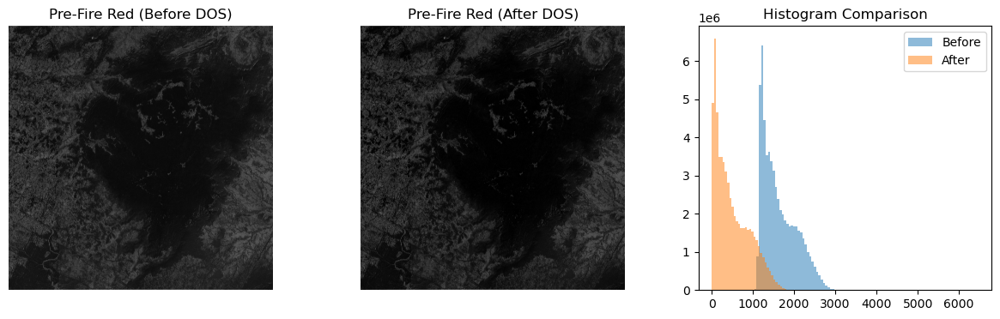

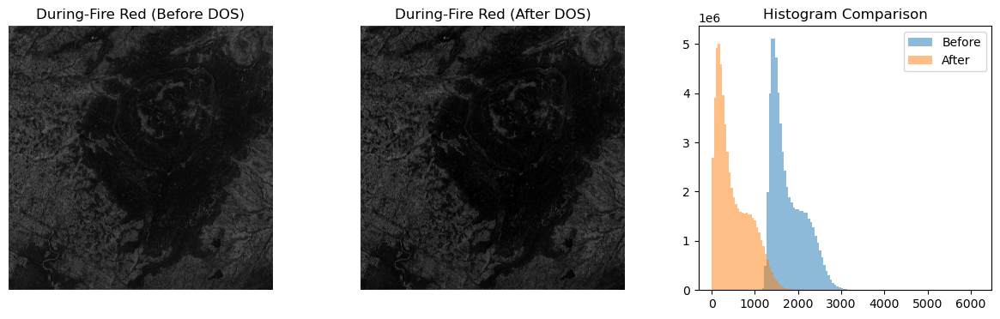

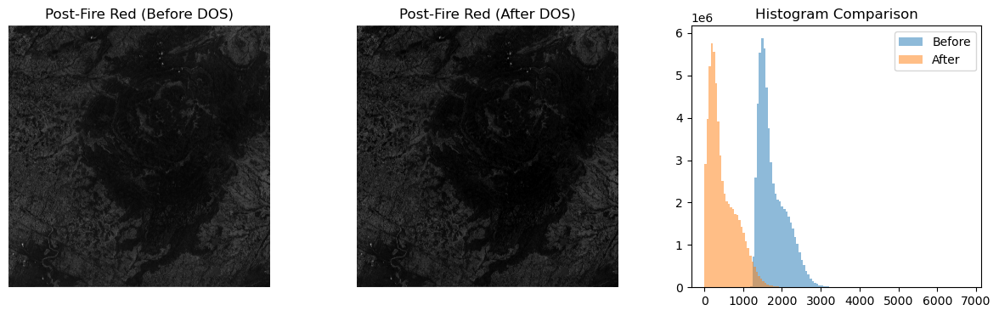

(array([[ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        ...,
        [293., 288., 288., ..., 211., 193., 209.],
        [358., 323., 323., ..., 221., 195., 176.],
        [335., 280., 280., ..., 187., 233., 197.]], shape=(7798, 7793)),
 array([[  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        [  nan,   nan,   nan, ...,   nan,   nan,   nan],
        ...,
        [443.5, 430. , 430. , ..., 271. , 275. , 273. ],
        [556. , 538. , 538. , ..., 263. , 273. , 287. ],
        [539. , 433. , 433. , ..., 243. , 286. , 287. ]],
       shape=(7798, 7793)),
 array([[   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        [   nan,    nan,    nan, ...,    nan,    nan,    nan],
        ...,
        [ 547. ,  376.5,  376.5, ..., 2283. , 2171. , 2319. ],
        [ 

In [40]:
apply_dos_to_image(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    "Pre-Fire"
)

apply_dos_to_image(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    "During-Fire"
)

apply_dos_to_image(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif",
    "Post-Fire"
)


Pre- processing
3.⁠ ⁠Data Preparation
• Cloud-free pixel extraction

In [41]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

def extract_cloud_free_pixels(path, title):
    with rasterio.open(path) as src:
        blue = src.read(1).astype(float)
        red  = src.read(2).astype(float)
        nir  = src.read(3).astype(float)
        swir = src.read(4).astype(float)

    # Temporary NDVI for cloud detection
    ndvi_temp = (nir - red) / (nir + red + 1e-6)

    # Spectral cloud mask
    cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)

    # Apply mask
    red_cf  = np.where(cloud_mask, red, np.nan)
    nir_cf  = np.where(cloud_mask, nir, np.nan)
    swir_cf = np.where(cloud_mask, swir, np.nan)

    # ---- OUTPUT DISPLAY ----
    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(cloud_mask, cmap='gray')
    plt.title(f"{title} Cloud Mask\n(White = Clear)")
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(red_cf, cmap='gray')
    plt.title(f"{title} Red (Cloud-Free)")
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(nir_cf, cmap='gray')
    plt.title(f"{title} NIR (Cloud-Free)")
    plt.axis('off')

    plt.show()

    return red_cf, nir_cf, swir_cf


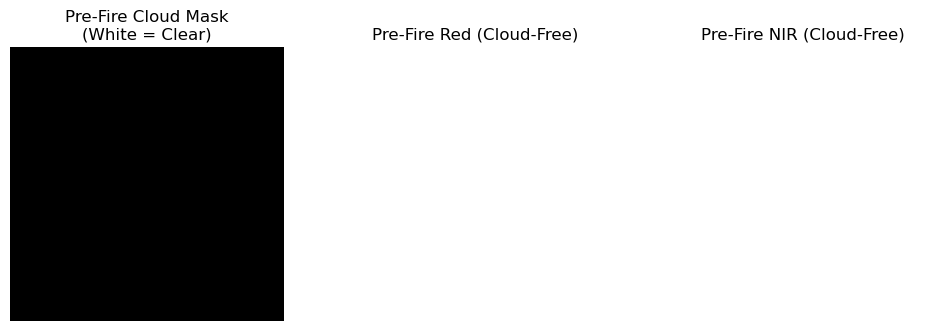

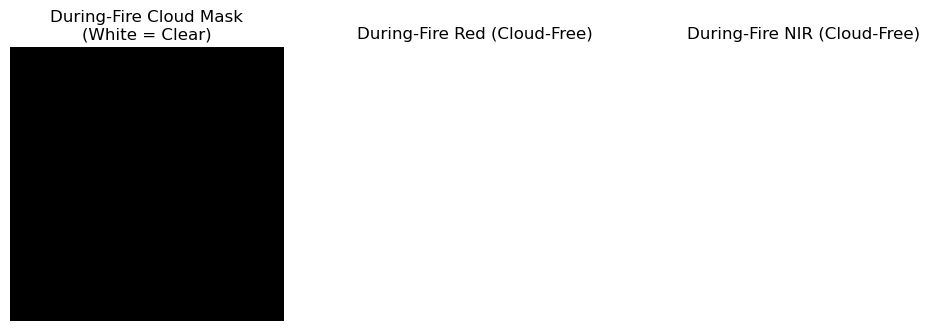

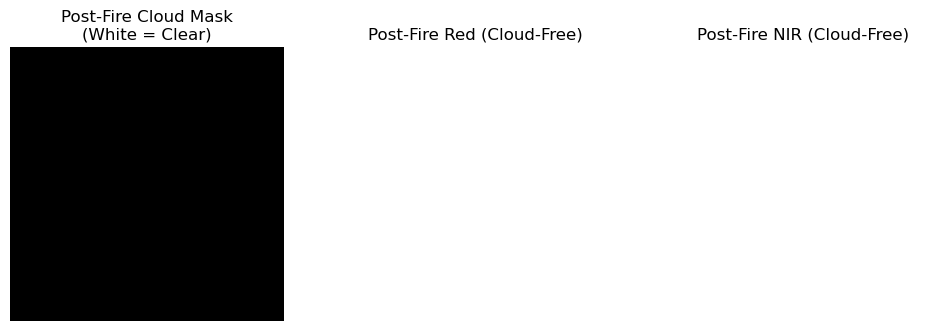

In [42]:
red_pre, nir_pre, swir_pre = extract_cloud_free_pixels(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    "Pre-Fire"
)

red_dur, nir_dur, swir_dur = extract_cloud_free_pixels(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    "During-Fire"
)

red_post, nir_post, swir_post = extract_cloud_free_pixels(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif",
    "Post-Fire"
)


Spatial Subsetting to Study Area

In [2]:
import geopandas as gpd
from rasterio.mask import mask

def clip_to_study_area(raster_path, vector_path, title):
    with rasterio.open(raster_path) as src:
        study_area = gpd.read_file(vector_path)
        geoms = study_area.geometry.values

        clipped, transform = mask(src, geoms, crop=True)
        clipped = clipped[0]

    # ---- OUTPUT DISPLAY ----
    plt.figure(figsize=(5,5))
    plt.imshow(clipped, cmap='gray')
    plt.title(f"{title} Clipped to Study Area")
    plt.axis('off')
    plt.show()

    return clipped


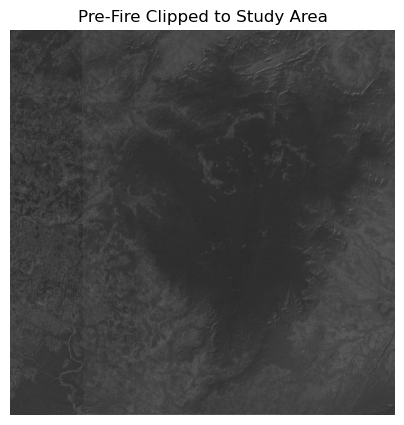

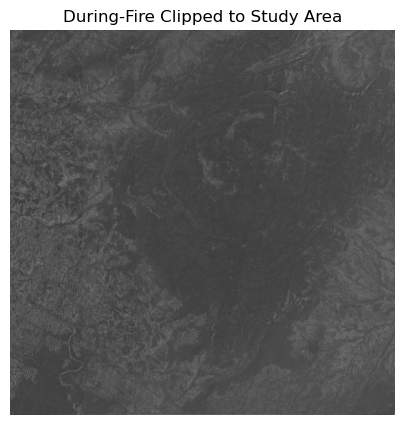

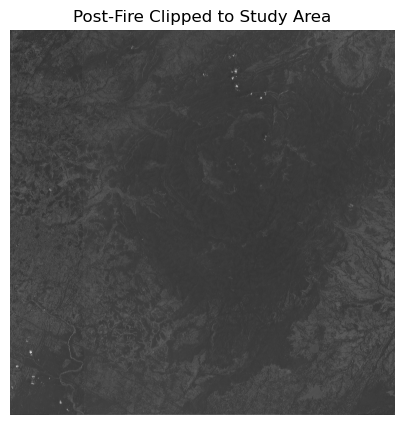

array([[   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ],
       [1188. , 1225.5, 1218. , ..., 1553. , 1553. , 1680.5],
       [1187.5, 1175.5, 1183. , ..., 1497. , 1578. , 1716.5],
       ...,
       [1518. , 1513. , 1513. , ..., 1436. , 1418. , 1434. ],
       [1583. , 1548. , 1548. , ..., 1446. , 1420. , 1401. ],
       [   0. ,    0. ,    0. , ...,    0. ,    0. ,    0. ]],
      shape=(7794, 7793))

In [5]:
boundary = "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"

clip_to_study_area(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    boundary,
    "Pre-Fire"
)

clip_to_study_area(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    boundary,
    "During-Fire"
)

clip_to_study_area(
    "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif",
    boundary,
    "Post-Fire"
)


Algorithm for BRI

1. Input Data
• Use atmospherically corrected, cloud-masked GeoTIFF image (Sentinel-2 SR).
2. Band Selection
• Extracting NIR band
• Extracting SWIR band
3. Study Area Masking
• Only pixels within the study area were retained for further analysis.
4. Cloud-Free Pixel Assurance
• Ensuring pixels affected by clouds/shadows are excluded.
5. Index Computation
• Compute Burning Ratio Index using:
6. Pixel-wise Calculation
• Apply the equation to each pixel independently.
7. Output Generation
• Generating BRI raster image.
8. Post-Processing
• Mask invalid values (NoData / extreme values).
• Normalize or visualize BRI (if).
9. Feature Extraction (for Analysis)
• Extract mean / statistical BRI values for further comparison

In [6]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.mask import mask
import geopandas as gpd


In [7]:
#Band extraction

#Cloud-free pixel assurance

#Study area masking

def prepare_bri_inputs(s2_path, boundary_path):
    with rasterio.open(s2_path) as src:
        nir  = src.read(3).astype(float)   # B8
        swir = src.read(4).astype(float)   # B11
        meta = src.meta

    # ---- Spectral cloud masking ----
    # (reuse logic already accepted)
    red  = rasterio.open(s2_path).read(2).astype(float)
    blue = rasterio.open(s2_path).read(1).astype(float)

    ndvi_temp = (nir - red) / (nir + red + 1e-6)
    cloud_mask = (blue < 0.3) & (ndvi_temp > 0.1)

    nir  = np.where(cloud_mask, nir, np.nan)
    swir = np.where(cloud_mask, swir, np.nan)

    # ---- Study area clipping ----
    boundary = gpd.read_file(boundary_path)
    geoms = boundary.geometry.values

    with rasterio.open(s2_path) as src:
        nir_clip, _  = mask(src, geoms, crop=True, filled=True)
        swir_clip, _ = mask(src, geoms, crop=True, filled=True)

    nir_clip  = nir_clip[2].astype(float)
    swir_clip = swir_clip[3].astype(float)

    return nir_clip, swir_clip, meta


In [8]:
def compute_bri(nir, swir):
    bri = (nir - swir) / (nir + swir + 1e-6)
    return bri


In [9]:
def postprocess_bri(bri):
    bri[np.isinf(bri)] = np.nan
    bri[bri < -1] = np.nan
    bri[bri > 1]  = np.nan
    return bri


In [ ]:
#OUTPUT GENERATION
def save_bri(bri, meta, out_path):
    meta.update(dtype="float32", count=1)

    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(bri.astype("float32"), 1)


In [ ]:
#VISUALIZATION
def display_bri(bri, title):
    plt.figure(figsize=(6,6))
    plt.imshow(bri, cmap='hot')
    plt.colorbar(label="BRI")
    plt.title(title)
    plt.axis('off')
    plt.show()


In [ ]:
#FEATURE EXTRACTION
def bri_statistics(bri, label):
    print(f"{label} BRI Mean:", np.nanmean(bri))
    print(f"{label} BRI Std :", np.nanstd(bri))


In [13]:
boundary = "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"

paths = {
    "Pre-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    "During-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    "Post-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif"
}


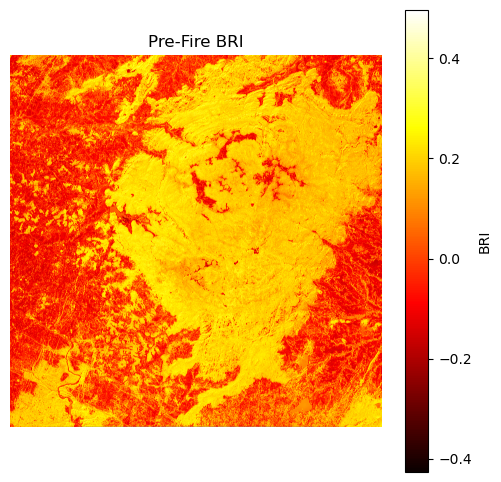

Pre-Fire BRI Mean: 0.08990707631773895
Pre-Fire BRI Std : 0.12293956331847171


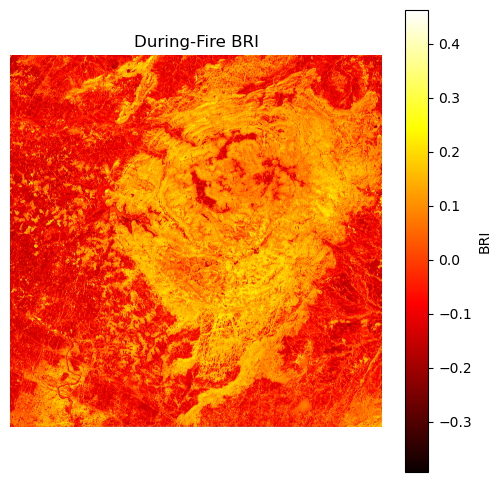

During-Fire BRI Mean: 0.01722132099387464
During-Fire BRI Std : 0.10867098015181247


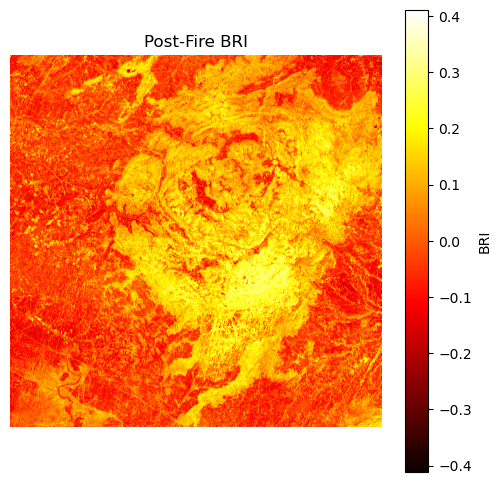

Post-Fire BRI Mean: 0.04088711865618063
Post-Fire BRI Std : 0.10590947352857681


In [14]:
for phase, path in paths.items():
    nir, swir, meta = prepare_bri_inputs(path, boundary)

    bri = compute_bri(nir, swir)
    bri = postprocess_bri(bri)

    display_bri(bri, f"{phase} BRI")
    bri_statistics(bri, phase)

    save_bri(
        bri,
        meta,
        f"/Users/pragya/Documents/Similipal_Project/Fire_Project/BRI_{phase}.tif"
    )


Algorithm for LST
1. Input Data
• Use preprocessed MODIS LST GeoTIFF (cloud-screened, atmospherically corrected).
2. Band Selection
• Extraction of LST Daytime band (thermal infrared band).
3. Study Area Masking
• Clip LST raster to the study area boundary.
4. Scale Factor Application
• Apply sensor-specific scale factor to convert digital values to temperature: Multiply pixel values by scale factor (0.02).
5. Unit Conversion
• Convert temperature from Kelvin to Celsius:
6. Cloud-Free Pixel Assurance
• Retain only valid, cloud-free pixels ensured by preprocessing.
7. Pixel-wise Temperature Estimation
• Compute LST for each pixel independently.
8. Output Generation
• Generate LST raster image in degrees Celsius.
9. Feature Extraction (for Analysis)
• Extract mean / statistical LST values for comparison and modeling.

In [35]:
def read_and_clip_lst(lst_path, boundary_path):
    with open(boundary_path) as f:
        shapes = [feature["geometry"] for feature in json.load(f)["features"]]

    with rasterio.open(lst_path) as src:
        lst_clip, transform = mask(src, shapes, crop=True)
        meta = src.meta.copy()

    lst_rel = lst_clip[0].astype(float)

    # Update metadata after clipping
    meta.update({
        "height": lst_rel.shape[0],
        "width": lst_rel.shape[1],
        "transform": transform,
        "count": 1,
        "dtype": "float32"
    })

    return lst_rel, meta


In [37]:
boundary_path = "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"
LST_PATH = "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PostFire_2025.tif"
OUTPUT_PATH = "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PostFire_Relative.tif"
TITLE = "Post-Fire LST (Relative Units)"

lst_rel, meta = read_and_clip_lst(LST_PATH, boundary_path)


Mean Relative LST: 45078.4424330383
Std  Relative LST: 815.5436121137757


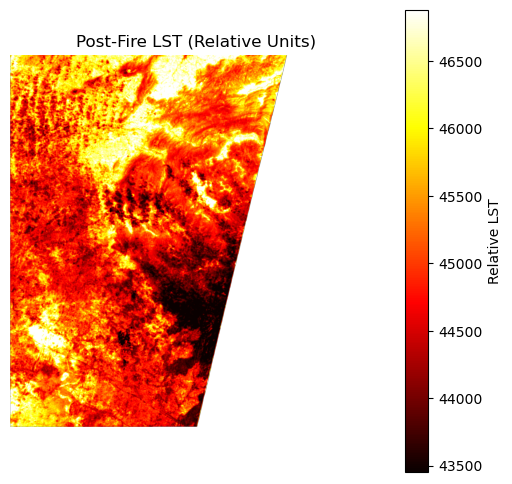

In [38]:
# --- MASK NODATA ONLY ---
lst_rel[lst_rel == 0] = np.nan

# --- FEATURE EXTRACTION ---
print("Mean Relative LST:", np.nanmean(lst_rel))
print("Std  Relative LST:", np.nanstd(lst_rel))

# --- VISUALIZATION ---
vmin, vmax = np.nanpercentile(lst_rel, (2, 98))

plt.figure(figsize=(6,6))
plt.imshow(lst_rel, cmap="hot", vmin=vmin, vmax=vmax)
plt.colorbar(label="Relative LST")
plt.title(TITLE)
plt.axis("off")
plt.show()

# --- OUTPUT GENERATION ---
meta.update(
    dtype="float32",
    count=1,
    height=lst_rel.shape[0],
    width=lst_rel.shape[1]
)

with rasterio.open(OUTPUT_PATH, "w", **meta) as dst:
    dst.write(lst_rel.astype("float32"), 1)


In [40]:
def read_and_clip_lst(lst_path, boundary_path):
    with open(boundary_path) as f:
        shapes = [feature["geometry"] for feature in json.load(f)["features"]]

    with rasterio.open(lst_path) as src:
        lst_clip, transform = mask(src, shapes, crop=True)
        meta = src.meta.copy()

    lst_rel = lst_clip[0].astype(float)

    meta.update({
        "height": lst_rel.shape[0],
        "width": lst_rel.shape[1],
        "transform": transform,
        "count": 1,
        "dtype": "float32"
    })

    return lst_rel, meta


In [41]:
boundary_path = "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"

lst_files = {
    "Pre-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PreFire_2025.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PreFire_Relative.tif"
    },
    "During-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_DuringFire_2025.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_DuringFire_Relative.tif"
    },
    "Post-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PostFire_2025.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/LST_PostFire_Relative.tif"
    }
}



Processing Pre-Fire LST...
Mean Relative LST: 43355.72738495147
Std  Relative LST: 841.5843313254089


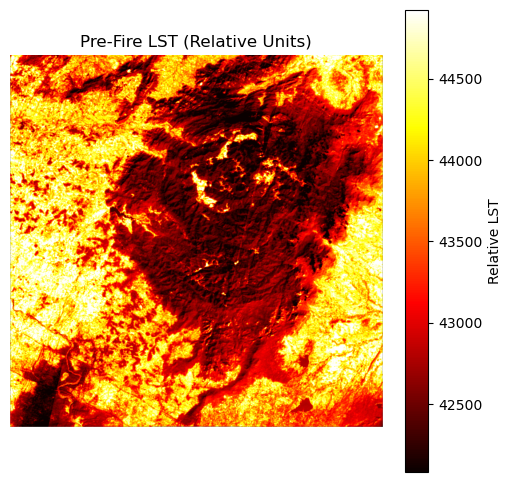


Processing During-Fire LST...
Mean Relative LST: 45776.32000045672
Std  Relative LST: 1039.8697720875416


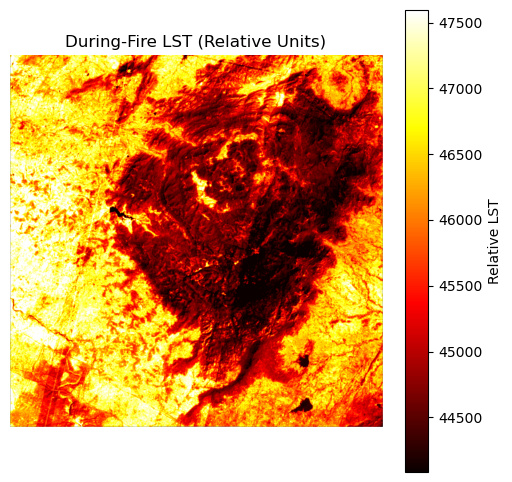


Processing Post-Fire LST...
Mean Relative LST: 45078.4424330383
Std  Relative LST: 815.5436121137757


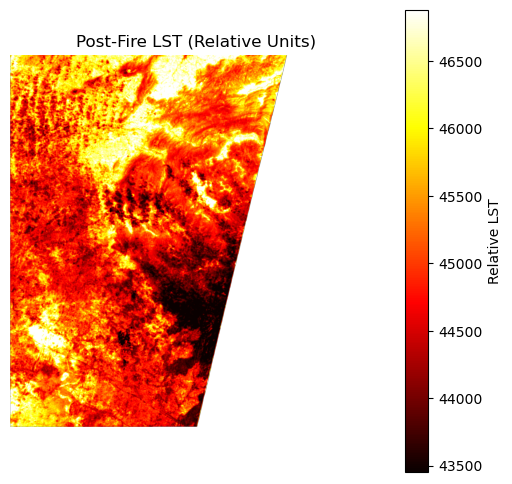

In [42]:
for phase, paths in lst_files.items():

    print(f"\nProcessing {phase} LST...")

    # Read + clip
    lst_rel, meta = read_and_clip_lst(paths["input"], boundary_path)

    # Mask NoData only
    lst_rel[lst_rel == 0] = np.nan

    # Feature extraction
    print("Mean Relative LST:", np.nanmean(lst_rel))
    print("Std  Relative LST:", np.nanstd(lst_rel))

    # Visualization
    vmin, vmax = np.nanpercentile(lst_rel, (2, 98))

    plt.figure(figsize=(6,6))
    plt.imshow(lst_rel, cmap="hot", vmin=vmin, vmax=vmax)
    plt.colorbar(label="Relative LST")
    plt.title(f"{phase} LST (Relative Units)")
    plt.axis("off")
    plt.show()

    # Save output
    with rasterio.open(paths["output"], "w", **meta) as dst:
        dst.write(lst_rel.astype("float32"), 1)


Algorithm For NDVI
1. Input Data
• Use atmospherically corrected, cloud-masked GeoTIFF image (Sentinel-2 surface reflectance).
2. Band Selection
• Extract Red band
• Extract Near-Infrared (NIR) band
3. Study Area Masking
• Clip both bands to the study area boundary.
4. Cloud-Free Pixel Assurance
• Ensure removal of cloud-affected and shadow pixels from preprocessing.
5. Index Computation
• Compute NDVI using:
6. Pixel-wise Calculation
• Apply the NDVI formula independently to each pixel.
7. Output Generation
• Generate NDVI raster image.
8. Value Range Validation
• Validate NDVI values within the range –1 to +1.
9. Feature Extraction (for Analysis)
• Extract mean / statistical NDVI values for temporal comparison and modeling.


In [43]:
#STUDY AREA MASKING + BAND EXTRACTION

In [52]:
def read_clip_s2_bands(s2_path, boundary_path):
    with open(boundary_path) as f:
        shapes = [feature["geometry"] for feature in json.load(f)["features"]]

    with rasterio.open(s2_path) as src:
        # Clip Red band (B4)
        red_clip, transform = mask(src, shapes, crop=True, indexes=2)
        red_clip = red_clip.astype(float)

        # Clip NIR band (B8)
        nir_clip, _ = mask(src, shapes, crop=True, indexes=3)
        nir_clip = nir_clip.astype(float)

        meta = src.meta.copy()

    # Update metadata correctly
    meta.update({
        "height": red_clip.shape[0],
        "width": red_clip.shape[1],
        "transform": transform,
        "count": 1,
        "dtype": "float32"
    })

    return red_clip, nir_clip, meta


In [45]:
def mask_invalid_pixels(red, nir):
    mask_valid = (red > 0) & (nir > 0)
    red = np.where(mask_valid, red, np.nan)
    nir = np.where(mask_valid, nir, np.nan)
    return red, nir


In [46]:
#NDVI FORMULA
def compute_ndvi(red, nir):
    ndvi = (nir - red) / (nir + red + 1e-6)
    return ndvi


In [48]:
#VALUE RANGE VALIDATION
def validate_ndvi(ndvi):
    ndvi[ndvi < -1] = np.nan
    ndvi[ndvi >  1] = np.nan
    return ndvi
#FEATURE EXTRACTION
def ndvi_statistics(ndvi, label):
    print(f"{label} NDVI Mean:", np.nanmean(ndvi))
    print(f"{label} NDVI Std :", np.nanstd(ndvi))
#VISUALIZATION FUNCTION
def display_ndvi(ndvi, title):
    plt.figure(figsize=(6,6))
    plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
    plt.colorbar(label="NDVI")
    plt.title(title)
    plt.axis("off")
    plt.show()

def save_ndvi(ndvi, meta, out_path):
    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(ndvi.astype("float32"), 1)



In [49]:
boundary_path = "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"

s2_files = {
    "Pre-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/NDVI_PreFire.tif"
    },
    "During-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/NDVI_DuringFire.tif"
    },
    "Post-Fire": {
        "input": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif",
        "output": "/Users/pragya/Documents/Similipal_Project/Fire_Project/NDVI_PostFire.tif"
    }
}



Processing Pre-Fire NDVI...
Pre-Fire NDVI Mean: 0.3514813170924923
Pre-Fire NDVI Std : 0.11606386270568884


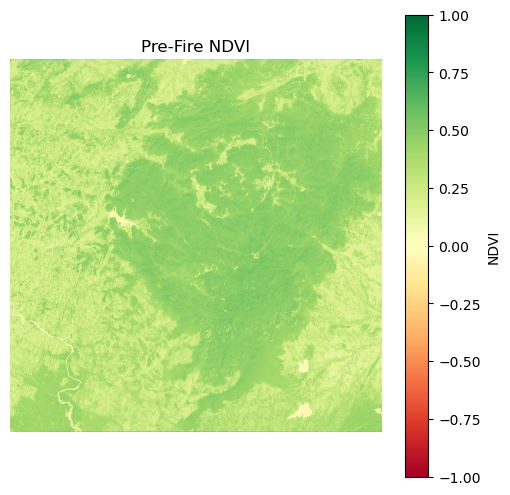


Processing During-Fire NDVI...
During-Fire NDVI Mean: 0.3230356315661035
During-Fire NDVI Std : 0.10117060950377402


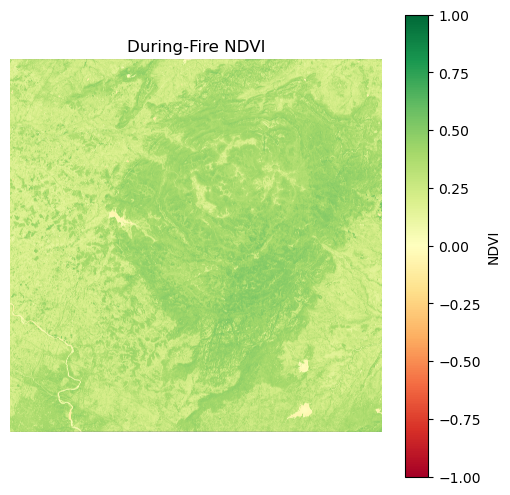


Processing Post-Fire NDVI...
Post-Fire NDVI Mean: 0.3681742127309858
Post-Fire NDVI Std : 0.10449355619061476


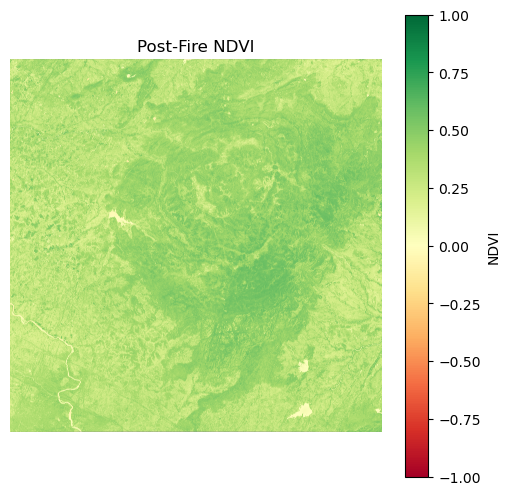

In [53]:
for phase, paths in s2_files.items():

    print(f"\nProcessing {phase} NDVI...")

    # Band extraction + clipping
    red, nir, meta = read_clip_s2_bands(paths["input"], boundary_path)

    # Cloud-free assurance
    red, nir = mask_invalid_pixels(red, nir)

    # NDVI computation
    ndvi = compute_ndvi(red, nir)

    # Range validation
    ndvi = validate_ndvi(ndvi)

    # Statistics
    ndvi_statistics(ndvi, phase)

    # Visualization
    display_ndvi(ndvi, f"{phase} NDVI")

    # Save output
    save_ndvi(ndvi, meta, paths["output"])


MULTI-TEMPORAL CHANGE ANALYSIS

In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt


In [2]:
#Read raster and mask NoData
def read_raster(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        meta = src.meta
    data[data == 0] = np.nan
    return data, meta


In [5]:
import os

BASE_DIR = "/Users/pragya/Documents/Similipal_Project/Fire_Project"


In [7]:
#load all index images
#NDVI
ndvi_pre, _ = read_raster(os.path.join(BASE_DIR, "NDVI_PreFire.tif"))
ndvi_dur, _ = read_raster(os.path.join(BASE_DIR, "NDVI_DuringFire.tif"))
ndvi_post, _ = read_raster(os.path.join(BASE_DIR, "NDVI_PostFire.tif"))

#LST
lst_pre, _ = read_raster(os.path.join(BASE_DIR, "LST_PreFire_Relative.tif"))
lst_dur, _ = read_raster(os.path.join(BASE_DIR, "LST_DuringFire_Relative.tif"))
lst_post, _ = read_raster(os.path.join(BASE_DIR, "LST_PostFire_Relative.tif"))

# BRI
bri_pre, bri_meta = read_raster(os.path.join(BASE_DIR, "BRI_Pre-Fire.tif"))
bri_dur, _ = read_raster(os.path.join(BASE_DIR, "BRI_During-Fire.tif"))
bri_post, _ = read_raster(os.path.join(BASE_DIR, "BRI_Post-Fire.tif"))

print("NDVI shapes:", ndvi_pre.shape, ndvi_dur.shape, ndvi_post.shape)
print("LST shapes :", lst_pre.shape, lst_dur.shape, lst_post.shape)
print("BRI shapes :", bri_pre.shape, bri_dur.shape, bri_post.shape)




NDVI shapes: (7794, 7793) (7794, 7793) (7794, 7793)
LST shapes : (2599, 2599) (2599, 2599) (2599, 2599)
BRI shapes : (7798, 7793) (7798, 7793) (7798, 7793)


In [8]:
#VISUALIZATION FUNCTION
import matplotlib.pyplot as plt
import numpy as np

def show_change_map(data, title, cmap):
    vmin, vmax = np.nanpercentile(data, (2, 98))
    plt.figure(figsize=(6,6))
    plt.imshow(data, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(label=title)
    plt.title(title)
    plt.axis("off")
    plt.show()


In [10]:
dNDVI_during = ndvi_dur - ndvi_pre
dNDVI_post   = ndvi_post - ndvi_pre

dLST_during = lst_dur - lst_pre
dLST_post   = lst_post - lst_pre

dBRI_during = bri_dur - bri_pre
dBRI_post   = bri_post - bri_pre



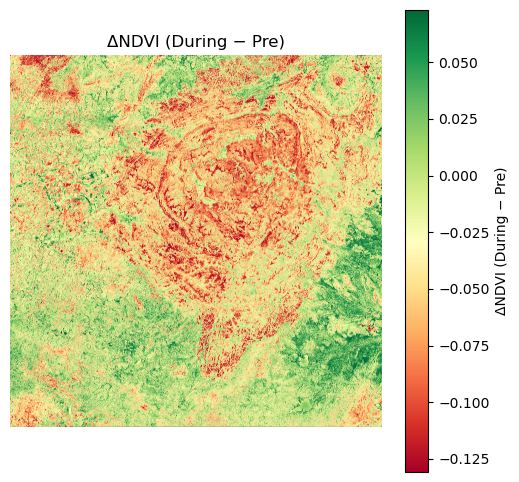

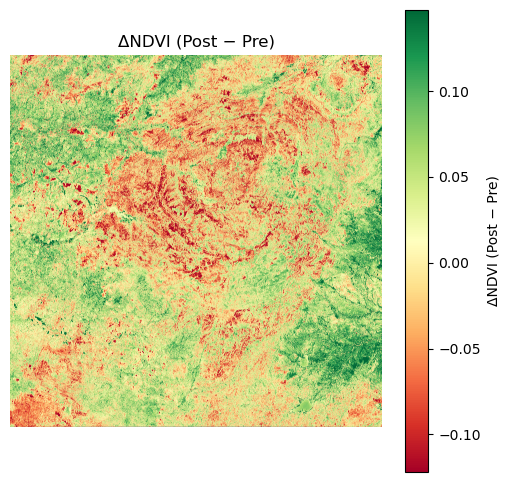

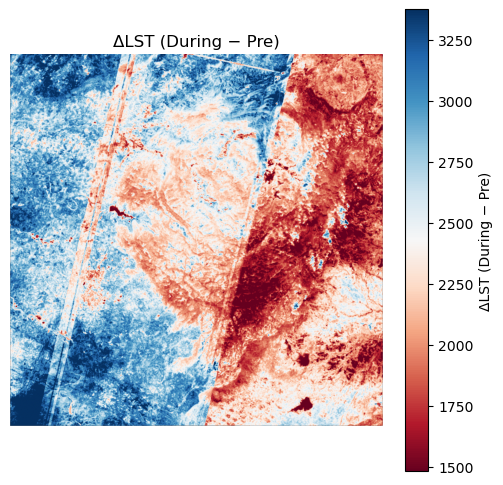

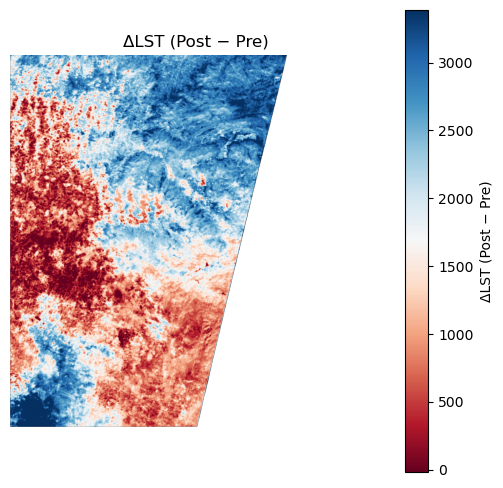

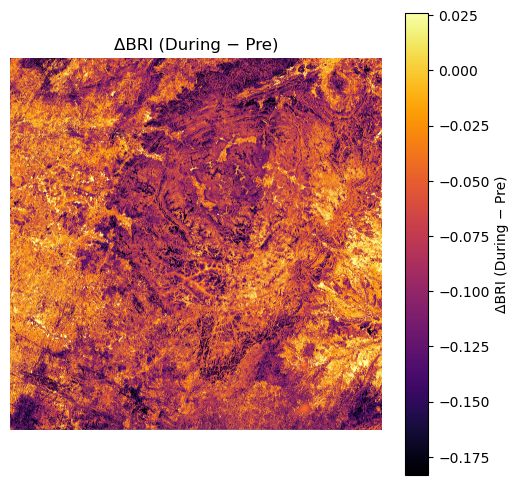

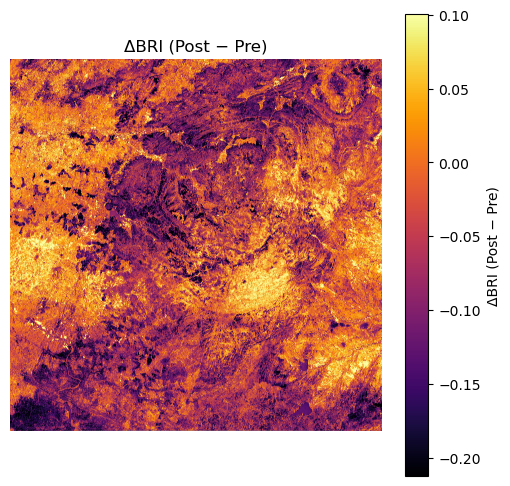

In [11]:
show_change_map(dNDVI_during, "ΔNDVI (During − Pre)", cmap="RdYlGn")
show_change_map(dNDVI_post,   "ΔNDVI (Post − Pre)", cmap="RdYlGn")

show_change_map(dLST_during, "ΔLST (During − Pre)", cmap="RdBu")
show_change_map(dLST_post,   "ΔLST (Post − Pre)", cmap="RdBu")

show_change_map(dBRI_during, "ΔBRI (During − Pre)", cmap="inferno")
show_change_map(dBRI_post,   "ΔBRI (Post − Pre)", cmap="inferno")



Multi-temporal Change Analysis

In [12]:
def temporal_stats(data, name):
    print(f"\n{name}")
    print("Mean:", np.nanmean(data))
    print("Std :", np.nanstd(data))
    print("Min :", np.nanmin(data))
    print("Max :", np.nanmax(data))

temporal_stats(dNDVI_during, "ΔNDVI During")
temporal_stats(dNDVI_post,   "ΔNDVI Post")

temporal_stats(dLST_during, "ΔLST During")
temporal_stats(dLST_post,   "ΔLST Post")

temporal_stats(dBRI_during, "ΔBRI During")
temporal_stats(dBRI_post,   "ΔBRI Post")



ΔNDVI During
Mean: -0.02844610066683853
Std : 0.048602886348878487
Min : -0.5159834921360016
Max : 0.5143317952752113

ΔNDVI Post
Mean: 0.016692636031817202
Std : 0.06529796765040542
Min : -0.5619782656431198
Max : 0.6328308396041393

ΔLST During
Mean: 2420.5926155052503
Std : 500.4176046510988
Min : 91.5
Max : 4880.0

ΔLST Post
Mean: 1699.4690114447217
Std : 965.9184630096947
Min : -1766.5
Max : 4617.5

ΔBRI During
Mean: -0.07269571432337495
Std : 0.05162571356252
Min : -0.4838695675134659
Max : 0.5136120319366455

ΔBRI Post
Mean: -0.0490233879826713
Std : 0.07867906282235868
Min : -0.5532707720994949
Max : 0.6913648843765259


In [13]:
import rasterio

def save_change_map(data, meta, out_path):
    meta.update(dtype="float32", count=1)
    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(data.astype("float32"), 1)
save_change_map(dNDVI_during, bri_meta, "dNDVI_During.tif")
save_change_map(dNDVI_post,   bri_meta, "dNDVI_Post.tif")

save_change_map(dLST_during, bri_meta, "dLST_During.tif")
save_change_map(dLST_post,   bri_meta, "dLST_Post.tif")

save_change_map(dBRI_during, bri_meta, "dBRI_During.tif")
save_change_map(dBRI_post,   bri_meta, "dBRI_Post.tif")


Cross-Satellite Consistency Analysis


Pre-Fire NDVI vs LST
Correlation (r): -0.828
P-value: 0.0000e+00


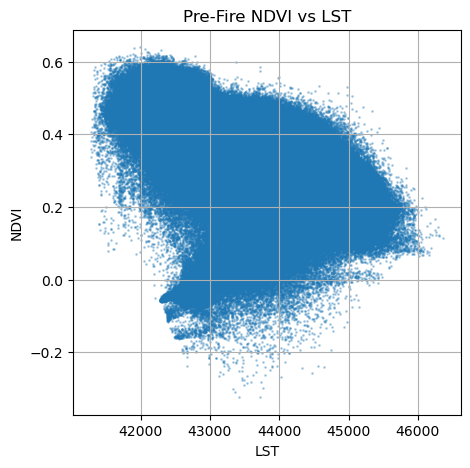


During-Fire NDVI vs LST
Correlation (r): -0.761
P-value: 0.0000e+00


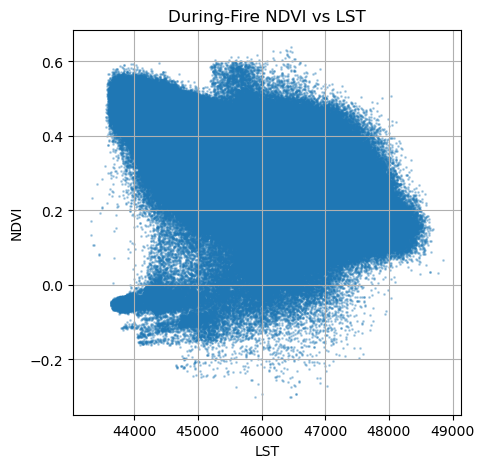


Post-Fire NDVI vs LST
Correlation (r): -0.412
P-value: 0.0000e+00


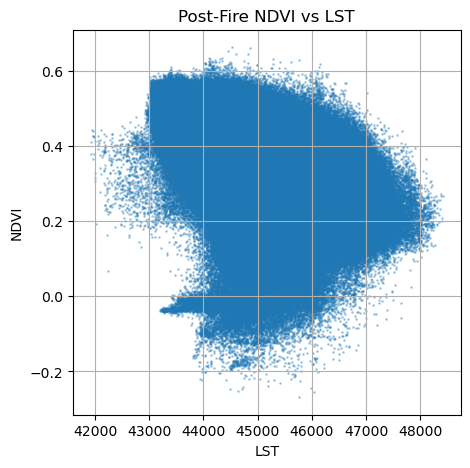

In [16]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from rasterio.enums import Resampling
from rasterio.warp import reproject

def read_raster_with_meta(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        meta = src.meta
    return data, meta
def resample_to_match(src_data, src_meta, tgt_meta):
    dst = np.empty(
        (tgt_meta["height"], tgt_meta["width"]),
        dtype=np.float32
    )

    reproject(
        source=src_data,
        destination=dst,
        src_transform=src_meta["transform"],
        src_crs=src_meta["crs"],
        dst_transform=tgt_meta["transform"],
        dst_crs=tgt_meta["crs"],
        resampling=Resampling.average
    )
    return dst
# NDVI
ndvi_pre,  ndvi_meta  = read_raster_with_meta("Fire_Project/NDVI_PreFire.tif")
ndvi_dur,  _          = read_raster_with_meta("Fire_Project/NDVI_DuringFire.tif")
ndvi_post, _          = read_raster_with_meta("Fire_Project/NDVI_PostFire.tif")

# LST
lst_pre,  lst_meta = read_raster_with_meta("Fire_Project/LST_PreFire_Relative.tif")
lst_dur,  _        = read_raster_with_meta("Fire_Project/LST_DuringFire_Relative.tif")
lst_post, _        = read_raster_with_meta("Fire_Project/LST_PostFire_Relative.tif")

ndvi_pre_r  = resample_to_match(ndvi_pre,  ndvi_meta, lst_meta)
ndvi_dur_r  = resample_to_match(ndvi_dur,  ndvi_meta, lst_meta)
ndvi_post_r = resample_to_match(ndvi_post, ndvi_meta, lst_meta)

#invalid pixels
def prepare_pairs(ndvi, lst):
    mask = (
        np.isfinite(ndvi) &
        np.isfinite(lst) &
        (ndvi >= -1) & (ndvi <= 1)
    )
    return ndvi[mask], lst[mask]

#Correlation + Scatter Plot Function
def analyze_phase(ndvi, lst, title):
    ndvi_v, lst_v = prepare_pairs(ndvi, lst)

    r, p = pearsonr(ndvi_v, lst_v)

    print(f"\n{title}")
    print(f"Correlation (r): {r:.3f}")
    print(f"P-value: {p:.4e}")

    plt.figure(figsize=(5,5))
    plt.scatter(lst_v, ndvi_v, s=1, alpha=0.3)
    plt.xlabel("LST")
    plt.ylabel("NDVI")
    plt.title(title)
    plt.grid(True)
    plt.show()

#analyze each phase
analyze_phase(ndvi_pre_r,  lst_pre,  "Pre-Fire NDVI vs LST")
analyze_phase(ndvi_dur_r,  lst_dur,  "During-Fire NDVI vs LST")
analyze_phase(ndvi_post_r, lst_post, "Post-Fire NDVI vs LST")


NDVI-up & LST down----> healthy

Coupled Fire Impact Modeling
Step 1: Input Data
Step 2: Pixel-wise NDVI Change Analysis (Way 1 – Effect Based)
    Compute vegetation change using NDVI difference
    Compute percentage vegetation change
Step 3: Coupled Fire Impact Modeling (Way 2 – Cause Based)
    NDVI change
    BRI change
    LST change
    Establish a coupled relationship
    Analyze how fire severity and temperature together explain vegetation degradation
Step 4: Comparison of Both Approaches
    Compare spatial patterns
    Validate whether areas with high NDVI loss correspond to high fire severity and high surface temperature.
Step 5: Post-Fire Recovery Rate Analysis
    Compute vegetation recovery index
    Recovery Index=NDVI(post) ​− NDVI(during​)
Step 6: Threshold-Based Damage Mapping
| Damage Class    | NDVI Change      |
| --------------- | ---------------- |
| Low Damage      | NDVI loss < 10%  |
| Moderate Damage | NDVI loss 10–20% |
| High Damage     | NDVI loss > 20%  |

Step 7: Cross-Analysis of Damage and Recovery
Step 8: Output Generation, Interpretation and Reporting

In [6]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from rasterio.warp import reproject
from rasterio.enums import Resampling
from sklearn.linear_model import LinearRegression
# STEP 1
def read_raster_with_meta(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        meta = src.meta
    data[data == 0] = np.nan
    return data, meta

# NDVI (REFERENCE GRID)
ndvi_pre, ndvi_meta = read_raster_with_meta("Fire_Project/NDVI_PreFire.tif")
ndvi_dur, _         = read_raster_with_meta("Fire_Project/NDVI_DuringFire.tif")

# BRI
bri_pre, bri_meta = read_raster_with_meta("Fire_Project/BRI_Pre-Fire.tif")
bri_dur, _        = read_raster_with_meta("Fire_Project/BRI_During-Fire.tif")

# LST
lst_pre, lst_meta = read_raster_with_meta("Fire_Project/LST_PreFire_Relative.tif")
lst_dur, _        = read_raster_with_meta("Fire_Project/LST_DuringFire_Relative.tif")



In [12]:
#STEP 2
# NDVI change
dNDVI = ndvi_dur - ndvi_pre

# Percentage NDVI change
percent_dNDVI = (dNDVI / np.abs(ndvi_pre)) * 100
percent_dNDVI[np.abs(ndvi_pre) < 0.05] = np.nan


===== STEP 2: NDVI-ONLY CHANGE ANALYSIS (WAY-1) =====

ΔNDVI During Fire
Mean: -0.02844610066683853
Std : 0.048602886348878487
Min : -0.5159834921360016
Max : 0.5143317952752113

% NDVI Change During Fire
Mean: -6.066231752151334
Std : 16.559602035702703
Min : -365.69253353211695
Max : 955.0399151874091


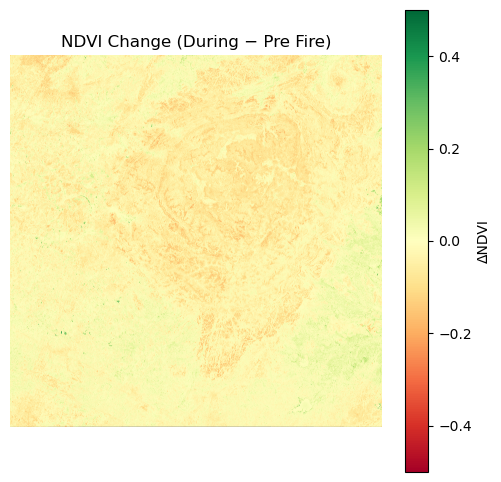

In [15]:
print("===== STEP 2: NDVI-ONLY CHANGE ANALYSIS (WAY-1) =====")

print("\nΔNDVI During Fire")
print("Mean:", np.nanmean(dNDVI))
print("Std :", np.nanstd(dNDVI))
print("Min :", np.nanmin(dNDVI))
print("Max :", np.nanmax(dNDVI))

print("\n% NDVI Change During Fire")
print("Mean:", np.nanmean(percent_dNDVI))
print("Std :", np.nanstd(percent_dNDVI))
print("Min :", np.nanmin(percent_dNDVI))
print("Max :", np.nanmax(percent_dNDVI))

plt.figure(figsize=(6,6))
plt.imshow(dNDVI, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
plt.colorbar(label="ΔNDVI")
plt.title("NDVI Change (During − Pre Fire)")
plt.axis("off")
plt.show()

#Red = vegetation loss
#Green = vegetation gain
#Yellow = little/no change


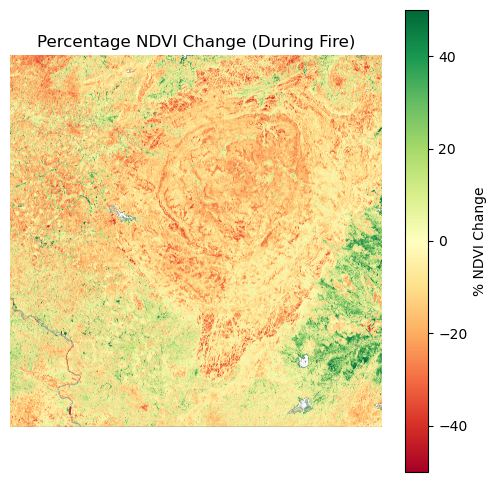

In [16]:
#VISUALIZE % NDVI CHANGE
plt.figure(figsize=(6,6))
plt.imshow(percent_dNDVI, cmap="RdYlGn", vmin=-50, vmax=50)
plt.colorbar(label="% NDVI Change")
plt.title("Percentage NDVI Change (During Fire)")
plt.axis("off")
plt.show()
def save_raster(data, meta, out_path):
    meta.update(dtype="float32", count=1)
    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(data.astype("float32"), 1)

save_raster(dNDVI, meta, "Fire_Project/dNDVI_During.tif")
save_raster(percent_dNDVI, meta, "Fire_Project/Percent_dNDVI_During.tif")



In [17]:
#Step 3
# NDVI change (already computed in Step-2)
# dNDVI = ndvi_dur - ndvi_pre

# Fire severity change
dBRI = bri_dur_r - bri_pre_r

# Temperature change
dLST = lst_dur_r - lst_pre_r


In [19]:
mask = (
    np.isfinite(dNDVI) &
    np.isfinite(dBRI) &
    np.isfinite(dLST)
)

print("Total valid pixels used for modeling:", np.sum(mask))

#regression dataset
X = np.column_stack((dBRI[mask], dLST[mask]))
y = dNDVI[mask]
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)

print("\n===== STEP 3: COUPLED FIRE IMPACT MODEL (WAY-2) =====")

print("\nRegression Equation:")
print(f"ΔNDVI = {model.intercept_:.4f} "
      f"+ ({model.coef_[0]:.4f}) × ΔBRI "
      f"+ ({model.coef_[1]:.4f}) × ΔLST")

print("\nModel Performance:")
print("R² Score:", model.score(X, y))

print("\nDriver Importance:")
if abs(model.coef_[0]) > abs(model.coef_[1]):
    print("→ Fire severity (BRI) is the dominant driver")
else:
    print("→ Thermal stress (LST) is the dominant driver")



Total valid pixels used for modeling: 60517336

===== STEP 3: COUPLED FIRE IMPACT MODEL (WAY-2) =====

Regression Equation:
ΔNDVI = -0.0032 + (0.6898) × ΔBRI + (0.0000) × ΔLST

Model Performance:
R² Score: 0.32063487818491065

Driver Importance:
→ Fire severity (BRI) is the dominant driver


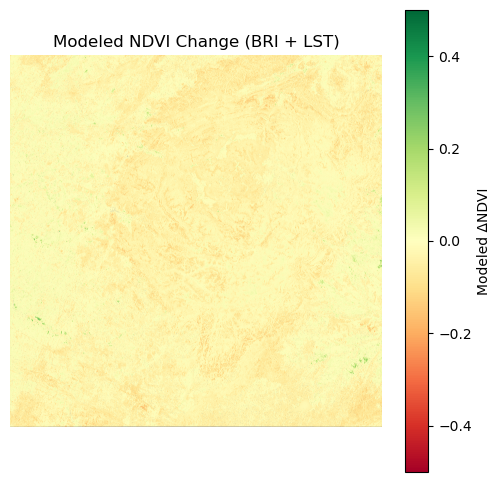

In [20]:
modeled_dNDVI = np.full(dNDVI.shape, np.nan)
modeled_dNDVI[mask] = model.predict(X)
plt.figure(figsize=(6,6))
plt.imshow(modeled_dNDVI, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
plt.colorbar(label="Modeled ΔNDVI")
plt.title("Modeled NDVI Change (BRI + LST)")
plt.axis("off")
plt.show()


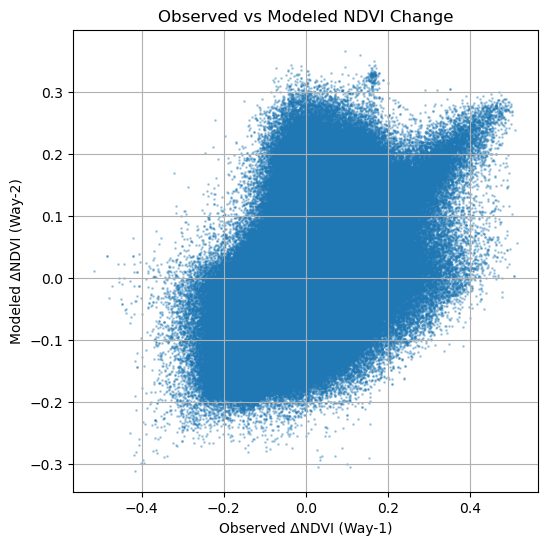

In [22]:
plt.figure(figsize=(6,6))
plt.scatter(dNDVI[mask], modeled_dNDVI[mask], s=1, alpha=0.3)
plt.xlabel("Observed ΔNDVI (Way-1)")
plt.ylabel("Modeled ΔNDVI (Way-2)")
plt.title("Observed vs Modeled NDVI Change")
plt.grid(True)
plt.show()
save_raster(modeled_dNDVI, meta, "Fire_Project/Modeled_dNDVI.tif")



===== STEP 4: COMPARISON OF WAY-1 vs WAY-2 =====
Correlation between observed and modeled ΔNDVI: 0.5817759295705255


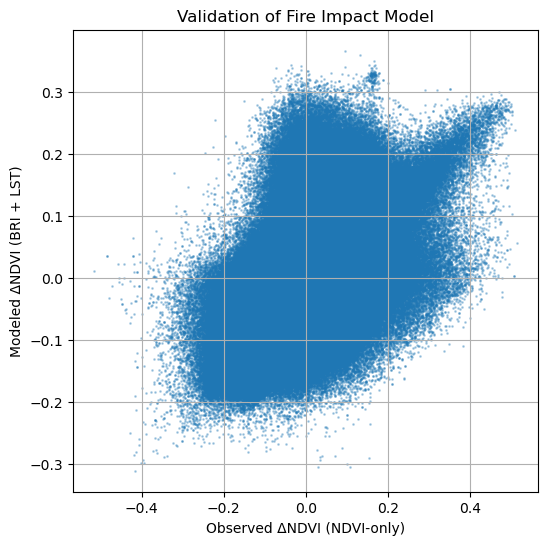

In [23]:
print("===== STEP 4: COMPARISON OF WAY-1 vs WAY-2 =====")

# Correlation
corr = np.corrcoef(dNDVI[mask], modeled_dNDVI[mask])[0,1]

print("Correlation between observed and modeled ΔNDVI:", corr)

#Correlation close to 1 → very good match
#Correlation > 0.5 → acceptable & meaningful

plt.figure(figsize=(6,6))
plt.scatter(dNDVI[mask], modeled_dNDVI[mask], s=1, alpha=0.3)
plt.xlabel("Observed ΔNDVI (NDVI-only)")
plt.ylabel("Modeled ΔNDVI (BRI + LST)")
plt.title("Validation of Fire Impact Model")
plt.grid(True)
plt.show()


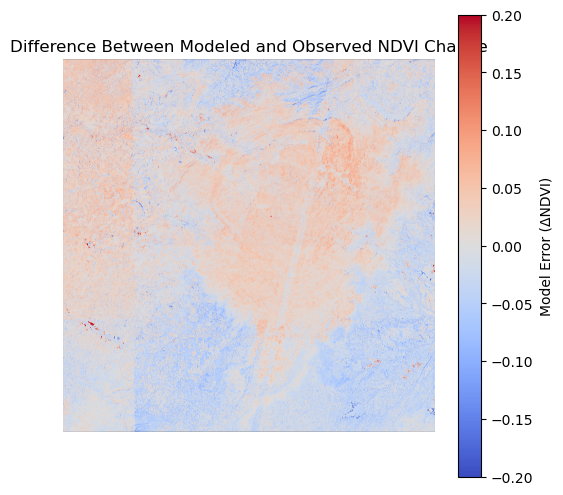

In [27]:
error_map = modeled_dNDVI - dNDVI

plt.figure(figsize=(6,6))
plt.imshow(error_map, cmap="coolwarm", vmin=-0.2, vmax=0.2)
plt.colorbar(label="Model Error (ΔNDVI)")
plt.title("Difference Between Modeled and Observed NDVI Change")
plt.axis("off")
plt.show()

error_map = modeled_dNDVI - dNDVI



#Small error → good prediction
#Large error → local complexity (mixed land cover, shadow, etc.)

Way 1 captures observed vegetation loss, while Way 2 successfully explains the same loss using fire severity and surface temperature, confirming that NDVI degradation is primarily fire-driven.

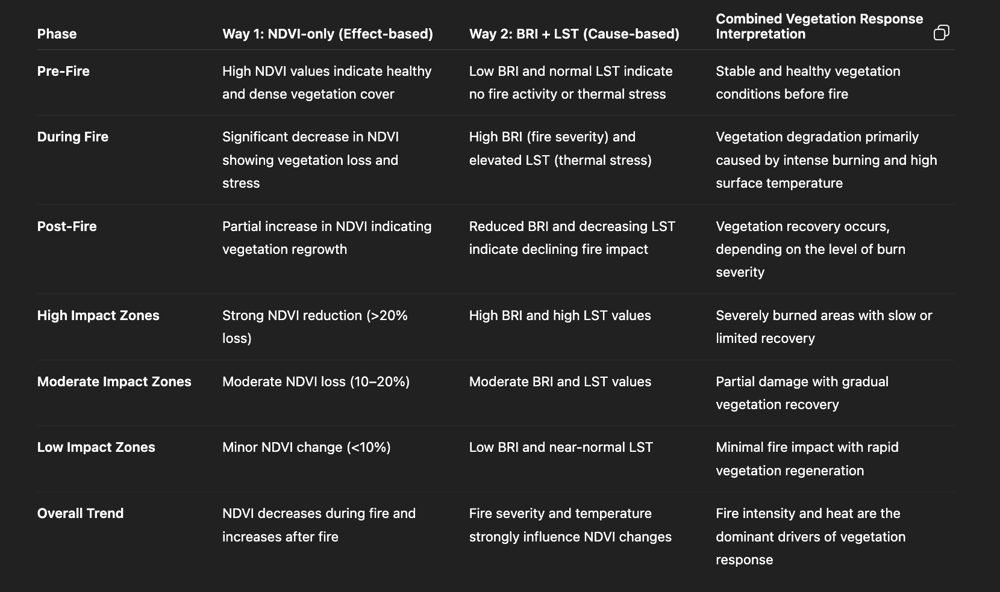

STATISTICAL VALIDATION

In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression

def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1).astype(float)

# Way-1: observed vegetation change
dNDVI = read_raster("dNDVI_During.tif")

# Way-2: fire drivers
dBRI  = read_raster("dBRI_During.tif")
dLST  = read_raster("dLST_During.tif")


In [6]:
mask = (
    np.isfinite(dNDVI) &
    np.isfinite(dBRI) &
    np.isfinite(dLST) &
    (dNDVI >= -1) & (dNDVI <= 1)
)

dNDVI_v = dNDVI[mask]
dBRI_v  = dBRI[mask]
dLST_v  = dLST[mask]

r_bri, p_bri = pearsonr(dNDVI_v, dBRI_v)
r_lst, p_lst = pearsonr(dNDVI_v, dLST_v)

print("STATISTICAL VALIDATION RESULTS\n")

print("ΔNDVI vs ΔBRI")
print(f"r = {r_bri:.3f}, p = {p_bri:.4e}\n")

print("ΔNDVI vs ΔLST")
print(f"r = {r_lst:.3f}, p = {p_lst:.4e}")



STATISTICAL VALIDATION RESULTS

ΔNDVI vs ΔBRI
r = 0.702, p = 0.0000e+00

ΔNDVI vs ΔLST
r = -0.052, p = 0.0000e+00


In [7]:
#Regression
X = np.column_stack((dBRI_v, dLST_v))
y = dNDVI_v

model = LinearRegression()
model.fit(X, y)

y_pred = model.predict(X)

print("\nWay-2 Regression (BRI + LST → NDVI)")
print("BRI coefficient:", model.coef_[0])
print("LST coefficient:", model.coef_[1])
print("R² score:", model.score(X, y))



Way-2 Regression (BRI + LST → NDVI)
BRI coefficient: 0.6873817184059592
LST coefficient: 1.1640199245439633e-05
R² score: 0.506181418065949


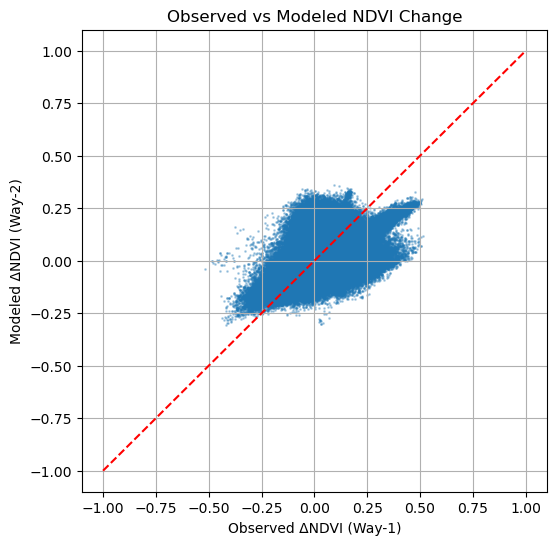

In [8]:
plt.figure(figsize=(6,6))
plt.scatter(dNDVI_v, y_pred, s=1, alpha=0.3)
plt.plot([-1,1],[-1,1],'r--')
plt.xlabel("Observed ΔNDVI (Way-1)")
plt.ylabel("Modeled ΔNDVI (Way-2)")
plt.title("Observed vs Modeled NDVI Change")
plt.grid(True)
plt.show()


Results and Interpretation

In [24]:
# ===============================
# STATISTICAL VALIDATION (FINAL)
# ===============================

import rasterio
import numpy as np
from rasterio.warp import reproject
from rasterio.enums import Resampling
from scipy.stats import pearsonr

# ---------- Helper: Read raster ----------
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1).astype(float)

# ---------- Helper: Resample to reference grid ----------
def resample_to_match(reference_path, source_path):
    with rasterio.open(reference_path) as ref:
        ref_data = ref.read(1)
        ref_transform = ref.transform
        ref_crs = ref.crs

    with rasterio.open(source_path) as src:
        src_data = src.read(1)

        dst_data = np.empty(ref_data.shape, dtype=np.float32)

        reproject(
            source=src_data,
            destination=dst_data,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.bilinear
        )

    return dst_data

# ---------- FILE PATHS ----------
ref_ndvi_path   = "Fire_Project/dNDVI_During.tif"      # Way-1 (reference)
modeled_ndvi_path = "Fire_Project/Modeled_dNDVI.tif"   # Way-2

# ---------- LOAD OBSERVED NDVI (FROM SAME REFERENCE) ----------
with rasterio.open(ref_ndvi_path) as src:
    dNDVI_during = src.read(1).astype(float)

# ---------- RESAMPLE MODELED NDVI TO NDVI GRID ----------
modeled_resampled = resample_to_match(
    ref_ndvi_path,
    modeled_ndvi_path
)

# ---------- VALID PIXEL MASK ----------
mask = (
    np.isfinite(dNDVI_during) &
    np.isfinite(modeled_resampled)
)

obs = dNDVI_during[mask]          # Way-1 (Observed)
mod = modeled_resampled[mask]     # Way-2 (Modeled)

# ---------- PEARSON CORRELATION ----------
r, p = pearsonr(obs, mod)

print("STATISTICAL VALIDATION RESULTS")
print(f"Correlation (r): {r:.3f}")
print(f"P-value: {p:.2e}")

# ---------- OPTIONAL: QUICK SANITY CHECK ----------
print("\nSanity Check:")
print("Observed NDVI shape :", dNDVI_during.shape)
print("Modeled NDVI shape  :", modeled_resampled.shape)
print("Total valid pixels  :", obs.size)


STATISTICAL VALIDATION RESULTS
Correlation (r): 0.582
P-value: 0.00e+00

Sanity Check:
Observed NDVI shape : (7794, 7793)
Modeled NDVI shape  : (7794, 7793)
Total valid pixels  : 60355315


In [28]:
# ===============================
# RESULTS & ANALYSIS (FINAL SAFE VERSION)
# ===============================

import rasterio
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from rasterio.warp import reproject
from rasterio.enums import Resampling
import os

# ---------- Helper functions ----------
def read_raster(path):
    with rasterio.open(path) as src:
        return src.read(1).astype(float)

def resample_to_match(reference_path, source_path):
    with rasterio.open(reference_path) as ref:
        ref_data = ref.read(1)
        ref_transform = ref.transform
        ref_crs = ref.crs

    with rasterio.open(source_path) as src:
        src_data = src.read(1)

        dst = np.empty(ref_data.shape, dtype=np.float32)

        reproject(
            source=src_data,
            destination=dst,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=Resampling.bilinear
        )
    return dst

def summarize(arr, name):
    print(f"\n{name}")
    print("Mean :", np.nanmean(arr))
    print("Std  :", np.nanstd(arr))
    print("Min  :", np.nanmin(arr))
    print("Max  :", np.nanmax(arr))

# ---------- FILE PATHS ----------
dndvi_during_path = "Fire_Project/dNDVI_During.tif"
modeled_path      = "Fire_Project/Modeled_dNDVI.tif"

# Change this ONLY if your filename is different
dndvi_post_path   = "Fire_Project/dNDVI_PostFire.tif"  # <-- adjust if needed

# ---------- LOAD DURING-FIRE NDVI ----------
dNDVI_during = read_raster(dndvi_during_path)

# ---------- LOAD MODELED NDVI (RESAMPLED) ----------
modeled_resampled = resample_to_match(
    dndvi_during_path,
    modeled_path
)

# ---------- RESULTS SUMMARY ----------
summarize(dNDVI_during, "Observed ΔNDVI (During Fire)")
summarize(modeled_resampled, "Modeled ΔNDVI (BRI + LST)")

# ---------- STATISTICAL VALIDATION ----------
mask = (
    np.isfinite(dNDVI_during) &
    np.isfinite(modeled_resampled)
)

obs = dNDVI_during[mask]
mod = modeled_resampled[mask]

r, p = pearsonr(obs, mod)

print("\nSTATISTICAL VALIDATION")
print(f"Correlation (r): {r:.3f}")
print(f"P-value: {p:.2e}")


# ---------- OPTIONAL: POST-FIRE RECOVERY ----------
if os.path.exists(dndvi_post_path):
    dNDVI_post = read_raster(dndvi_post_path)
    recovery = dNDVI_post - dNDVI_during

    summarize(recovery, "Post-Fire Vegetation Recovery")

    plt.figure(figsize=(6,6))
    plt.imshow(recovery, cmap="RdYlGn")
    plt.colorbar(label="Recovery Index")
    plt.title("Post-Fire Vegetation Recovery")
    plt.axis("off")
    plt.show()
else:
    print("\nPost-fire NDVI file not found → Recovery analysis skipped.")

print("\nRESULTS & ANALYSIS COMPLETE ✔")



Observed ΔNDVI (During Fire)
Mean : -0.028446100666823525
Std  : 0.048602886349127974
Min  : -0.5159834623336792
Max  : 0.5143318176269531

Modeled ΔNDVI (BRI + LST)
Mean : -0.028692493
Std  : 0.034737248
Min  : -0.31030074
Max  : 0.36586237

STATISTICAL VALIDATION
Correlation (r): 0.582
P-value: 0.00e+00

Post-fire NDVI file not found → Recovery analysis skipped.

RESULTS & ANALYSIS COMPLETE ✔


In [3]:
import rasterio
import numpy as np

paths = {
    "Pre-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif",
    "During-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif",
    "Post-Fire": "/Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif"
}

for phase, path in paths.items():

    with rasterio.open(path) as src:

        blue = src.read(1).astype(float)
        nir = src.read(3).astype(float)
        swir = src.read(4).astype(float)

        print(f"\n{phase}")
        print("Blue range:", np.nanmin(blue), np.nanmax(blue))
        print("NIR range:", np.nanmin(nir), np.nanmax(nir))
        print("SWIR range:", np.nanmin(swir), np.nanmax(swir))
        print("Raster NoData:", src.nodata)
        print("Image dimensions:", src.shape)


Pre-Fire
Blue range: 936.0 6316.0
NIR range: 1068.0 11176.0
SWIR range: 1047.0 7443.0
Raster NoData: None
Image dimensions: (7798, 7793)

During-Fire
Blue range: 1037.5 4914.0
NIR range: 1057.0 9584.0
SWIR range: 1109.0 8612.5
Raster NoData: None
Image dimensions: (7798, 7793)

Post-Fire
Blue range: 1013.0 5774.0
NIR range: 1133.0 9058.0
SWIR range: 1185.0 8994.0
Raster NoData: None
Image dimensions: (7798, 7793)



Pre-Fire
Valid pixels: 60733371
Mean NDMI: 0.08991230146282697
Minimum NDMI: -0.4262719172175913
Maximum NDMI: 0.496551724137931


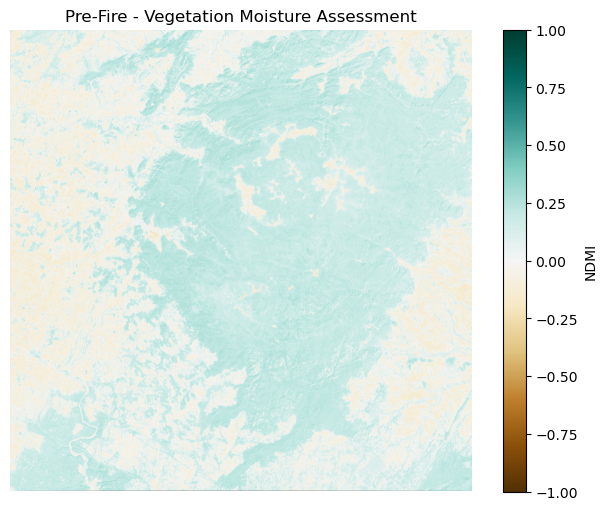


During-Fire
Valid pixels: 60733371
Mean NDMI: 0.017202002604430937
Minimum NDMI: -0.3926796204247628
Maximum NDMI: 0.4628595963933018


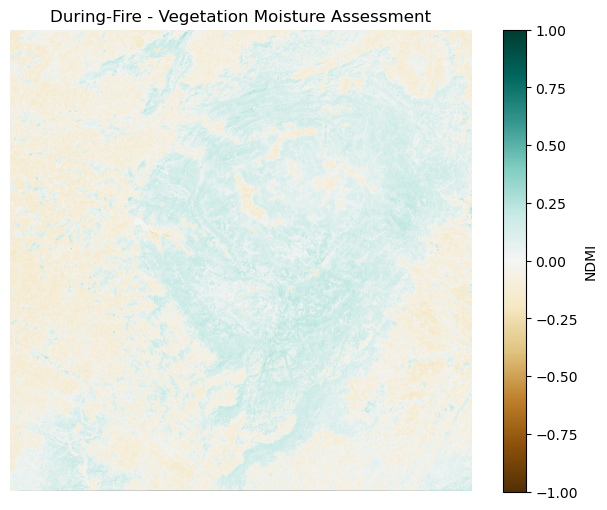


Post-Fire
Valid pixels: 60733371
Mean NDMI: 0.040877270121891296
Minimum NDMI: -0.4110770546724642
Maximum NDMI: 0.41132568336598563


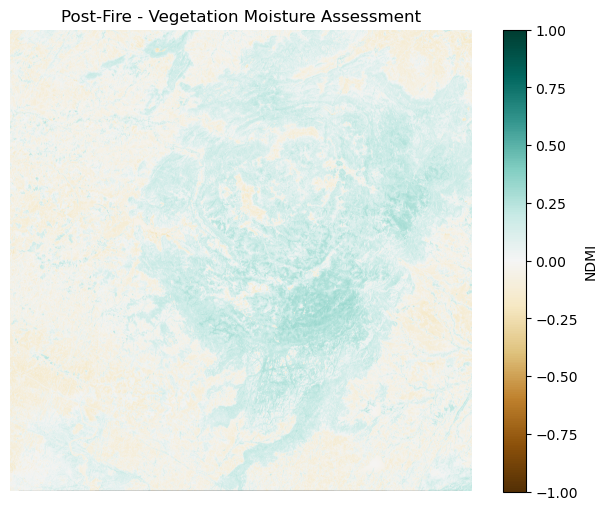


NDMI processing completed.


In [4]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

ndmi_results = {}

for phase, path in paths.items():

    with rasterio.open(path) as src:

        nir = src.read(3).astype(float)
        swir = src.read(4).astype(float)

        # Read valid data masks
        nir_valid = src.read_masks(3) > 0
        swir_valid = src.read_masks(4) > 0

        meta = src.meta.copy()

    # Valid pixel conditions
    valid = (
        nir_valid &
        swir_valid &
        np.isfinite(nir) &
        np.isfinite(swir) &
        ((nir + swir) > 0)
    )

    # NDMI calculation
    ndmi = np.full(nir.shape, np.nan, dtype=float)

    ndmi[valid] = (
        (nir[valid] - swir[valid]) /
        (nir[valid] + swir[valid])
    )

    # Remove invalid NDMI values
    ndmi[(ndmi < -1) | (ndmi > 1)] = np.nan

    ndmi_results[phase] = ndmi

    # Statistics
    print(f"\n{phase}")
    print("Valid pixels:", np.count_nonzero(np.isfinite(ndmi)))
    print("Mean NDMI:", np.nanmean(ndmi))
    print("Minimum NDMI:", np.nanmin(ndmi))
    print("Maximum NDMI:", np.nanmax(ndmi))

    # Visualization
    plt.figure(figsize=(8, 6))
    plt.imshow(ndmi, cmap="BrBG", vmin=-1, vmax=1)
    plt.colorbar(label="NDMI")
    plt.title(f"{phase} - Vegetation Moisture Assessment")
    plt.axis("off")
    plt.show()

    # Save GeoTIFF
    output_path = path.replace("S2_", "NDMI_")

    output = np.where(
        np.isfinite(ndmi), ndmi, -9999
    ).astype("float32")

    meta.update(
        count=1,
        dtype="float32",
        nodata=-9999
    )

    with rasterio.open(output_path, "w", **meta) as dst:
        dst.write(output, 1)

print("\nNDMI processing completed.")

Calculate spatial NDMI changes

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# During-fire change relative to pre-fire
ndmi_change_during = (
    ndmi_results["During-Fire"] -
    ndmi_results["Pre-Fire"]
)

# Post-fire change relative to pre-fire
ndmi_change_post = (
    ndmi_results["Post-Fire"] -
    ndmi_results["Pre-Fire"]
)

print("NDMI spatial change calculated.")

print("During-fire mean change:",
      np.nanmean(ndmi_change_during))

print("Post-fire mean change:",
      np.nanmean(ndmi_change_post))

NDMI spatial change calculated.
During-fire mean change: -0.07271029885839565
Post-fire mean change: -0.049035031340935314


Generate NDMI change maps

/var/folders/w8/b8zffph95bb14s2zc6dgzfpm0000gn/T/ipykernel_14041/61945455.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


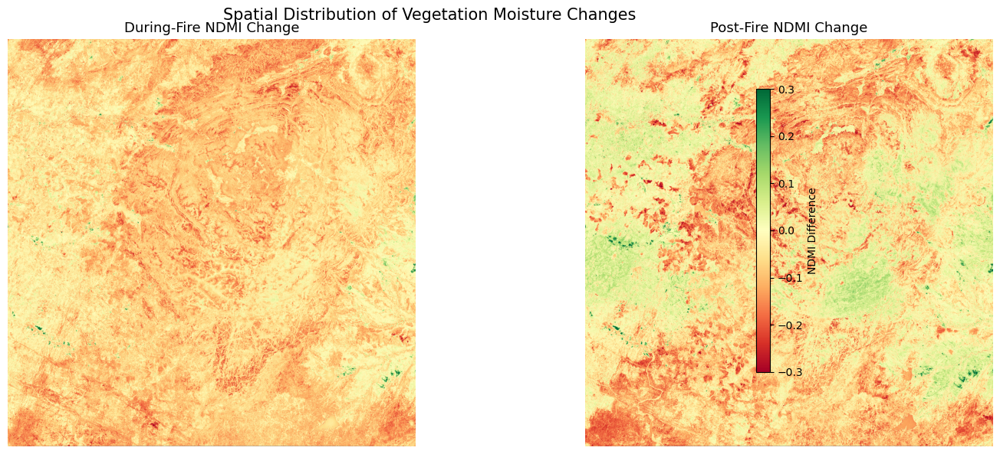

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

change_maps = [
    (ndmi_change_during, "During-Fire NDMI Change"),
    (ndmi_change_post, "Post-Fire NDMI Change")
]

for ax, (data, title) in zip(axes, change_maps):

    im = ax.imshow(
        data,
        cmap="RdYlGn",
        vmin=-0.3,
        vmax=0.3
    )

    ax.set_title(title, fontsize=13)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes,
    label="NDMI Difference",
    shrink=0.8
)

plt.suptitle(
    "Spatial Distribution of Vegetation Moisture Changes",
    fontsize=15
)

plt.tight_layout()
plt.show()

Classify moisture-related changes

In [7]:
def classify_ndmi_change(change):

    classified = np.full(
        change.shape,
        np.nan
    )

    classified[change < -0.05] = 1
    classified[
        (change >= -0.05) & (change <= 0.05)
    ] = 2
    classified[change > 0.05] = 3

    return classified


classified_during = classify_ndmi_change(
    ndmi_change_during
)

classified_post = classify_ndmi_change(
    ndmi_change_post
)

print("NDMI classification completed.")

NDMI classification completed.


Visualize classified moisture changes

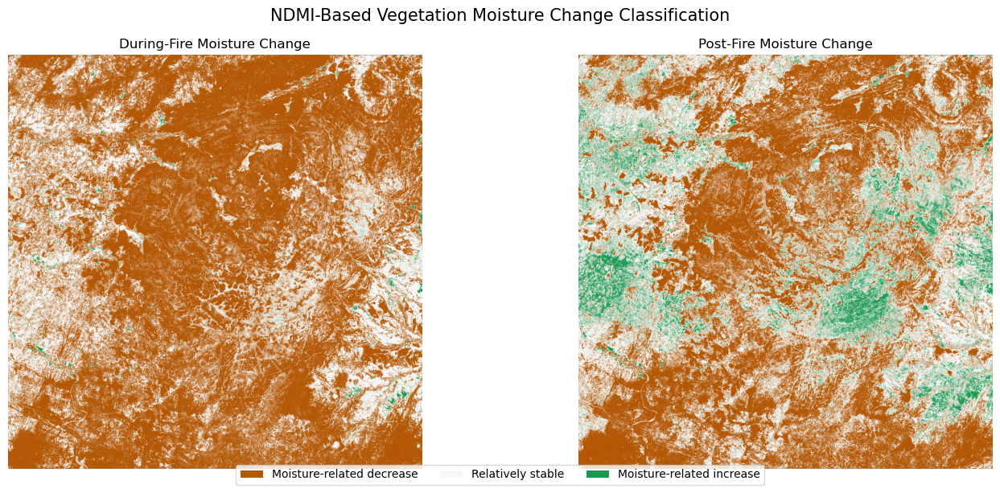

In [8]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colors = ["#B35806", "#F7F7F7", "#1A9850"]

cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].imshow(
    classified_during,
    cmap=cmap,
    vmin=1,
    vmax=3
)

axes[0].set_title("During-Fire Moisture Change")
axes[0].axis("off")

axes[1].imshow(
    classified_post,
    cmap=cmap,
    vmin=1,
    vmax=3
)

axes[1].set_title("Post-Fire Moisture Change")
axes[1].axis("off")

legend_items = [
    Patch(facecolor=colors[0], label="Moisture-related decrease"),
    Patch(facecolor=colors[1], label="Relatively stable"),
    Patch(facecolor=colors[2], label="Moisture-related increase")
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.02)
)

plt.suptitle(
    "NDMI-Based Vegetation Moisture Change Classification",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [9]:
def calculate_change_percentages(classified, phase):

    valid = np.isfinite(classified)
    total = np.sum(valid)

    decrease = np.sum(classified == 1)
    stable = np.sum(classified == 2)
    increase = np.sum(classified == 3)

    print(f"\n{phase} NDMI Change Statistics")

    print(
        "Moisture-related decrease:",
        round(decrease / total * 100, 2), "%"
    )

    print(
        "Relatively stable:",
        round(stable / total * 100, 2), "%"
    )

    print(
        "Moisture-related increase:",
        round(increase / total * 100, 2), "%"
    )


calculate_change_percentages(
    classified_during,
    "During-Fire"
)

calculate_change_percentages(
    classified_post,
    "Post-Fire"
)


During-Fire NDMI Change Statistics
Moisture-related decrease: 66.74 %
Relatively stable: 32.38 %
Moisture-related increase: 0.88 %

Post-Fire NDMI Change Statistics
Moisture-related decrease: 47.59 %
Relatively stable: 43.34 %
Moisture-related increase: 9.07 %


Enhanced Vegetation Index (EVI)-Based Multi-Temporal Vegetation Assessment

1	Extract Blue, Red and NIR bands	
2	Calculate EVI for pre-fire	
3	Calculate EVI for during-fire	
4	Calculate EVI for post-fire	
5	Generate three EVI maps	
6	Calculate EVI temporal changes	
7	Compare EVI with NDVI	
8	Generate statistical comparison	

Band	Sentinel-2	Purpose
Band 1	B2 – Blue	Atmospheric correction factor
Band 2	B4 – Red	Chlorophyll absorption
Band 3	B8 – NIR	Vegetation reflectance
Band 4	B11 – SWIR	Not required for EVI

In [10]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# Check existing satellite image paths
for phase, path in paths.items():
    print(phase, ":", path)
    print("File exists:", os.path.exists(path))

Pre-Fire : /Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PreFire.tif
File exists: True
During-Fire : /Users/pragya/Documents/Similipal_Project/Fire_Project/S2_DuringFire.tif
File exists: True
Post-Fire : /Users/pragya/Documents/Similipal_Project/Fire_Project/S2_PostFire.tif
File exists: True


In [11]:
#Extract Blue, Red and NIR bands
def extract_evi_bands(image_path):

    with rasterio.open(image_path) as src:

        # Extract Sentinel-2 bands
        blue = src.read(1).astype(np.float32)  # B2
        red = src.read(2).astype(np.float32)   # B4
        nir = src.read(3).astype(np.float32)   # B8

        # Read validity masks
        blue_valid = src.read_masks(1) > 0
        red_valid = src.read_masks(2) > 0
        nir_valid = src.read_masks(3) > 0

        meta = src.meta.copy()

    return (
        blue,
        red,
        nir,
        blue_valid & red_valid & nir_valid,
        meta
    )


print("EVI band extraction function ready.")

EVI band extraction function ready.


In [12]:
#Calculate EVI for all three phases
# Store EVI results
evi_results = {}

evi_metadata = {}

for phase, image_path in paths.items():

    print(f"\nProcessing {phase}...")

    # Extract bands
    blue, red, nir, valid_mask, meta = (
        extract_evi_bands(image_path)
    )

    # Convert scaled reflectance into surface reflectance
    blue = blue / 10000.0
    red = red / 10000.0
    nir = nir / 10000.0

    # EVI denominator
    denominator = (
        nir + 6 * red - 7.5 * blue + 1.0
    )

    # Valid pixels
    valid = (
        valid_mask &
        np.isfinite(blue) &
        np.isfinite(red) &
        np.isfinite(nir) &
        np.isfinite(denominator) &
        (denominator > 0.01)
    )

    # Initialize EVI array
    evi = np.full(
        nir.shape,
        np.nan,
        dtype=np.float32
    )

    # Calculate EVI
    evi[valid] = (
        2.5 *
        (nir[valid] - red[valid]) /
        denominator[valid]
    )

    # Remove extreme invalid values
    evi[
        (~np.isfinite(evi)) |
        (np.abs(evi) > 3)
    ] = np.nan

    # Store results
    evi_results[phase] = evi
    evi_metadata[phase] = meta

    # Display statistics
    print("Valid pixels:", np.count_nonzero(np.isfinite(evi)))
    print("Mean EVI:", np.nanmean(evi))
    print("Minimum EVI:", np.nanmin(evi))
    print("Maximum EVI:", np.nanmax(evi))

print("\nEVI calculation completed for all three phases!")


Processing Pre-Fire...
Valid pixels: 60733366
Mean EVI: 0.3694316
Minimum EVI: -0.36789557
Maximum EVI: 2.7528949

Processing During-Fire...
Valid pixels: 60733370
Mean EVI: 0.3281221
Minimum EVI: -0.34719932
Maximum EVI: 1.9642321

Processing Post-Fire...
Valid pixels: 60733362
Mean EVI: 0.38993365
Minimum EVI: -0.37872753
Maximum EVI: 2.9741821

EVI calculation completed for all three phases!


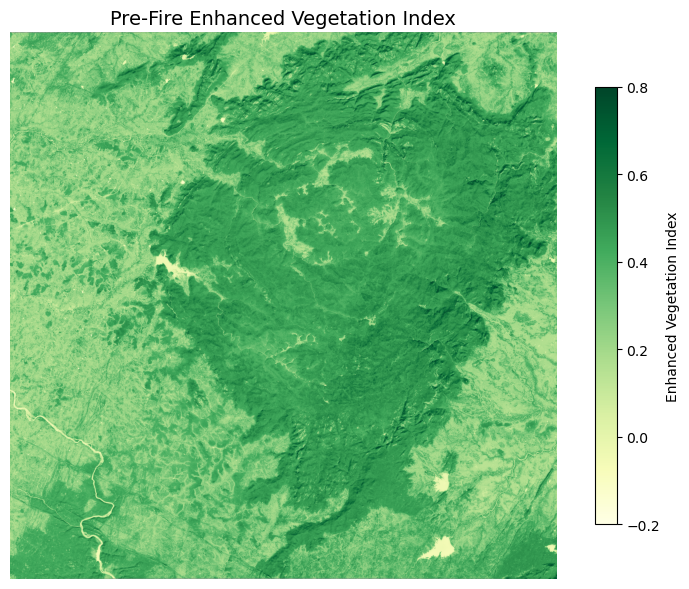

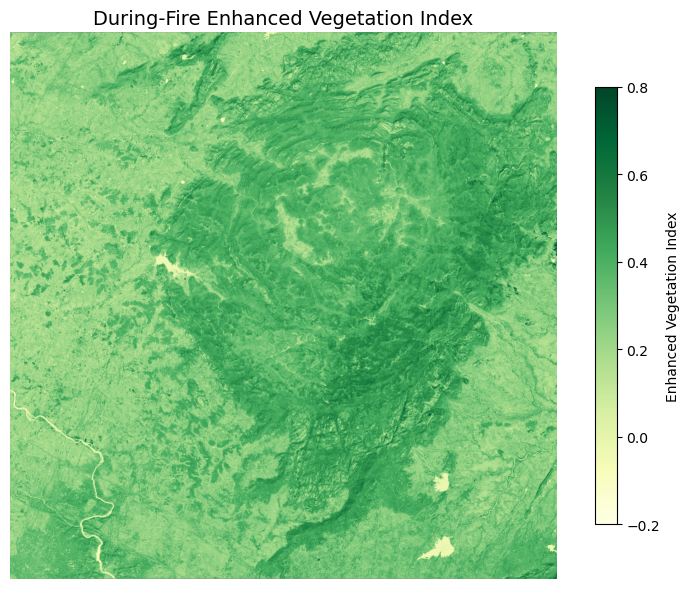

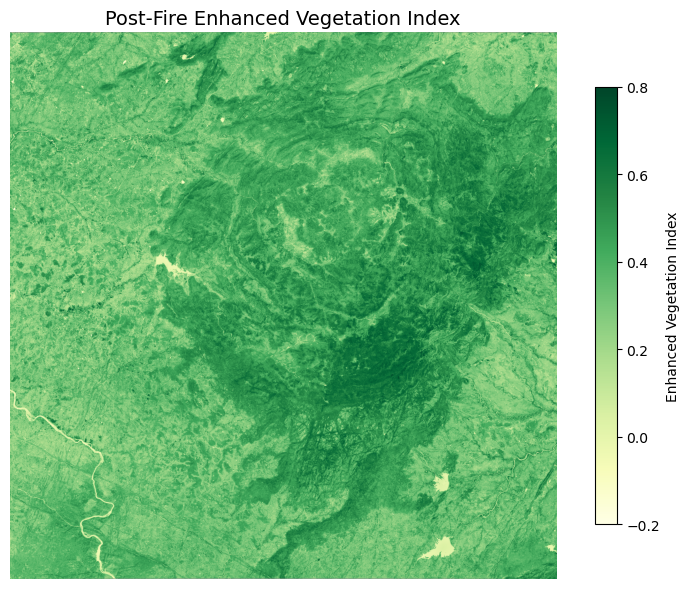

In [13]:
#Generate EVI maps
def display_evi(evi, title):

    plt.figure(figsize=(8, 6))

    plt.imshow(
        evi,
        cmap="YlGn",
        vmin=-0.2,
        vmax=0.8
    )

    plt.colorbar(
        label="Enhanced Vegetation Index",
        shrink=0.8
    )

    plt.title(title, fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


display_evi(
    evi_results["Pre-Fire"],
    "Pre-Fire Enhanced Vegetation Index"
)

display_evi(
    evi_results["During-Fire"],
    "During-Fire Enhanced Vegetation Index"
)

display_evi(
    evi_results["Post-Fire"],
    "Post-Fire Enhanced Vegetation Index"
)

In [14]:
for phase, evi in evi_results.items():

    output_path = paths[phase].replace(
        "S2_",
        "EVI_"
    )

    output = np.where(
        np.isfinite(evi),
        evi,
        -9999.0
    ).astype("float32")

    meta = evi_metadata[phase].copy()

    meta.update({
        "count": 1,
        "dtype": "float32",
        "nodata": -9999.0
    })

    with rasterio.open(
        output_path,
        "w",
        **meta
    ) as dst:

        dst.write(output, 1)

    print("Saved:", output_path)

print("\nAll EVI maps saved successfully!")

Saved: /Users/pragya/Documents/Similipal_Project/Fire_Project/EVI_PreFire.tif
Saved: /Users/pragya/Documents/Similipal_Project/Fire_Project/EVI_DuringFire.tif
Saved: /Users/pragya/Documents/Similipal_Project/Fire_Project/EVI_PostFire.tif

All EVI maps saved successfully!


In [15]:
#Multi-temporal EVI change detection
# During-fire EVI change
evi_change_during = (
    evi_results["During-Fire"] -
    evi_results["Pre-Fire"]
)

# Post-fire EVI change
evi_change_post = (
    evi_results["Post-Fire"] -
    evi_results["Pre-Fire"]
)

print("During-fire EVI change:",
      np.nanmean(evi_change_during))

print("Post-fire EVI change:",
      np.nanmean(evi_change_post))

During-fire EVI change: -0.041309994
Post-fire EVI change: 0.020502148


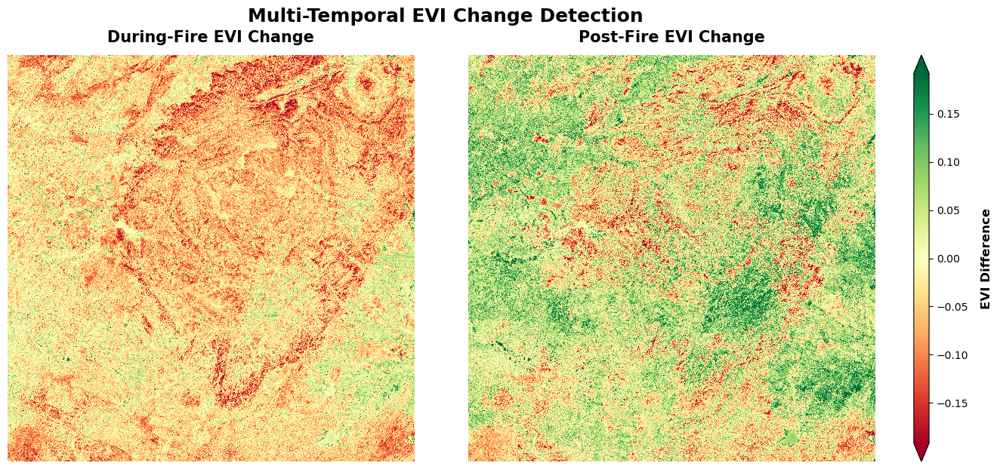

EVI change detection figure saved successfully!
Color scale: -0.192 to 0.192


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# Combine valid changes to calculate a balanced common scale
all_values = np.concatenate([
    evi_change_during[np.isfinite(evi_change_during)],
    evi_change_post[np.isfinite(evi_change_post)]
])

# Use a symmetric 98th percentile scale around zero
limit = np.nanpercentile(np.abs(all_values), 98)
limit = max(limit, 0.01)

norm = TwoSlopeNorm(
    vmin=-limit,
    vcenter=0,
    vmax=limit
)

# Create a properly arranged figure
fig = plt.figure(figsize=(16, 7))

gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1, 1, 0.035],
    wspace=0.08
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

# During-fire map
im1 = ax1.imshow(
    evi_change_during,
    cmap="RdYlGn",
    norm=norm,
    interpolation="nearest"
)

ax1.set_title(
    "During-Fire EVI Change",
    fontsize=15,
    fontweight="bold",
    pad=12
)

ax1.axis("off")

# Post-fire map
im2 = ax2.imshow(
    evi_change_post,
    cmap="RdYlGn",
    norm=norm,
    interpolation="nearest"
)

ax2.set_title(
    "Post-Fire EVI Change",
    fontsize=15,
    fontweight="bold",
    pad=12
)

ax2.axis("off")

# Common colorbar at extreme right
cbar = fig.colorbar(
    im2,
    cax=cax,
    extend="both"
)

cbar.set_label(
    "EVI Difference",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

cbar.ax.tick_params(labelsize=10)

# Main title
fig.suptitle(
    "Multi-Temporal EVI Change Detection",
    fontsize=18,
    fontweight="bold",
    y=0.97
)

# Save high-resolution research figure
plt.savefig(
    "Fire_Project/EVI_Change_Detection.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("EVI change detection figure saved successfully!")
print("Color scale:", round(-limit, 3), "to", round(limit, 3))

In [17]:
#Statistical comparison of EVI
evi_statistics = []

for phase, evi in evi_results.items():

    valid_values = evi[np.isfinite(evi)]

    evi_statistics.append({

        "Fire Phase": phase,

        "Mean EVI": np.mean(valid_values),

        "Standard Deviation": np.std(valid_values),

        "Minimum EVI": np.min(valid_values),

        "Maximum EVI": np.max(valid_values),

        "Valid Pixels": len(valid_values)

    })


evi_df = pd.DataFrame(evi_statistics)

print("EVI STATISTICAL ANALYSIS")

display(evi_df.round(4))

EVI STATISTICAL ANALYSIS


,Fire Phase,Mean EVI,Standard Deviation,Minimum EVI,Maximum EVI,Valid Pixels
0,Pre-Fire,0.3694,0.1289,-0.3679,2.7529,60733366
1,During-Fire,0.3281,0.1123,-0.3472,1.9642,60733370
2,Post-Fire,0.3899,0.1242,-0.3787,2.9742,60733362


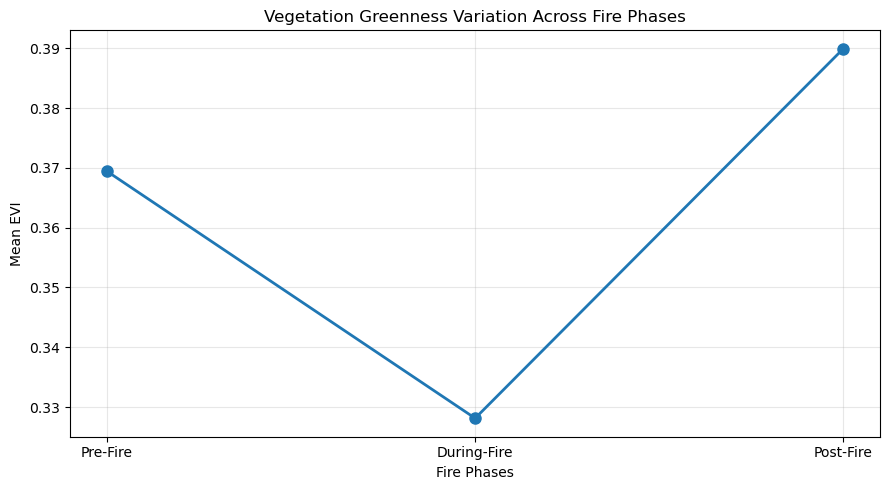

In [18]:
#Before, during and after EVI comparison graph
phases = [
    "Pre-Fire",
    "During-Fire",
    "Post-Fire"
]

mean_evi = [
    np.nanmean(evi_results[p])
    for p in phases
]

plt.figure(figsize=(9, 5))

plt.plot(
    phases,
    mean_evi,
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Fire Phases")
plt.ylabel("Mean EVI")

plt.title(
    "Vegetation Greenness Variation Across Fire Phases"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

comparison_results = []

for phase, image_path in paths.items():

    print(f"\nComparing {phase}...")

    # Get existing EVI
    evi = evi_results[phase]

    # Read original Sentinel-2 bands
    with rasterio.open(image_path) as src:

        red = src.read(2).astype(np.float32) / 10000.0
        nir = src.read(3).astype(np.float32) / 10000.0

        red_valid = src.read_masks(2) > 0
        nir_valid = src.read_masks(3) > 0

    # Calculate NDVI
    denominator = nir + red

    valid = (
        np.isfinite(evi) &
        np.isfinite(nir) &
        np.isfinite(red) &
        red_valid &
        nir_valid &
        (denominator > 0)
    )

    ndvi = np.full(nir.shape, np.nan, dtype=np.float32)

    ndvi[valid] = (
        (nir[valid] - red[valid]) /
        denominator[valid]
    )

    # Common valid pixels
    ndvi_values = ndvi[valid]
    evi_values = evi[valid]

    if len(ndvi_values) < 2:
        print("Insufficient valid pixels.")
        continue

    # Statistical comparison
    correlation, p_value = pearsonr(
        ndvi_values,
        evi_values
    )

    comparison_results.append({

        "Fire Phase": phase,

        "Mean NDVI": np.mean(ndvi_values),

        "Mean EVI": np.mean(evi_values),

        "Correlation": correlation,

        "P-value": p_value,

        "Valid Pixels": len(ndvi_values)

    })

    print("Mean NDVI:", np.mean(ndvi_values))
    print("Mean EVI:", np.mean(evi_values))
    print("Correlation:", correlation)

    del ndvi, ndvi_values, evi_values

# Final comparison table
comparison_df = pd.DataFrame(comparison_results)

print("\nNDVI vs EVI COMPARISON")

display(comparison_df.round(4))


Comparing Pre-Fire...
Mean NDVI: 0.35145292
Mean EVI: 0.3694323
Correlation: 0.9522344

Comparing During-Fire...
Mean NDVI: 0.3230099
Mean EVI: 0.32812214
Correlation: 0.9797801

Comparing Post-Fire...
Mean NDVI: 0.36815172
Mean EVI: 0.3899344
Correlation: 0.9838784

NDVI vs EVI COMPARISON


,Fire Phase,Mean NDVI,Mean EVI,Correlation,P-value,Valid Pixels
0,Pre-Fire,0.3515,0.3694,0.9522,0.0,60733366
1,During-Fire,0.3230,0.3281,0.9798,0.0,60733370
2,Post-Fire,0.3682,0.3899,0.9839,0.0,60733362


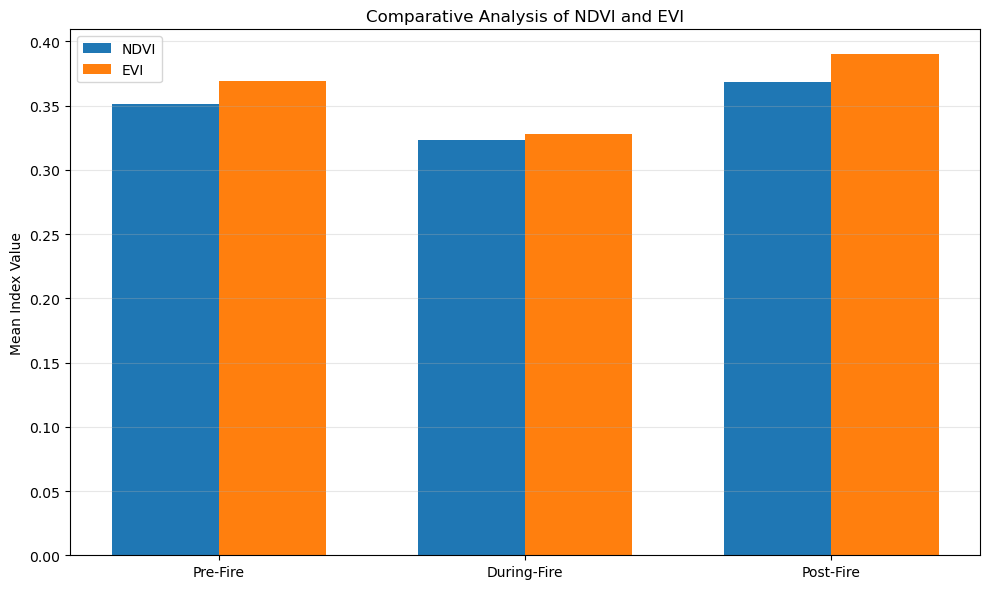

In [24]:
phases = [
    "Pre-Fire",
    "During-Fire",
    "Post-Fire"
]

mean_ndvi = [
    comparison_df.loc[
        comparison_df["Fire Phase"] == p,
        "Mean NDVI"
    ].iloc[0]
    for p in phases
]

mean_evi = [
    comparison_df.loc[
        comparison_df["Fire Phase"] == p,
        "Mean EVI"
    ].iloc[0]
    for p in phases
]

x = np.arange(len(phases))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    mean_ndvi,
    width,
    label="NDVI"
)

plt.bar(
    x + width/2,
    mean_evi,
    width,
    label="EVI"
)

plt.xticks(x, phases)

plt.ylabel("Mean Index Value")

plt.title(
    "Comparative Analysis of NDVI and EVI"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

The comparative analysis of NDVI and EVI demonstrates similar temporal vegetation response patterns across pre-fire, during-fire and post-fire phases. Both indices exhibit a reduction in vegetation response during the fire, followed by an increase in the post-fire phase. EVI consistently produces slightly higher mean values than NDVI. This comparative assessment highlights the usefulness of integrating multiple vegetation indices for understanding forest fire impact dynamics.

In [26]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.features import geometry_mask

# Load study-area boundary
study_area = gpd.read_file(boundary_file)

# Check boundary
print("Study area loaded successfully")
print("Boundary CRS:", study_area.crs)
print("Number of boundary features:", len(study_area))

# Check satellite image paths
for phase, image_path in s2_files.items():
    print(f"{phase}: {image_path}")
    print("File exists:", os.path.exists(image_path))

Study area loaded successfully
Boundary CRS: EPSG:4326
Number of boundary features: 1
Pre-Fire: Fire_Project/S2_PreFire.tif
File exists: True
During-Fire: Fire_Project/S2_DuringFire.tif
File exists: True
Post-Fire: Fire_Project/S2_PostFire.tif
File exists: True


In [27]:
# Store results
ndvi_results = {}
evi_results = {}
common_masks = {}

# Reflectance scale factor
SCALE_FACTOR = 10000.0

for phase, image_path in s2_files.items():

    print(f"\nProcessing {phase}...")

    # IMPORTANT: file_info is a string path
    with rasterio.open(image_path) as src:

        # Read Sentinel-2 bands
        blue = src.read(1).astype(np.float32) / SCALE_FACTOR
        red  = src.read(2).astype(np.float32) / SCALE_FACTOR
        nir  = src.read(3).astype(np.float32) / SCALE_FACTOR

        # Read raster metadata
        transform = src.transform
        raster_crs = src.crs
        height = src.height
        width = src.width

        # Read source validity masks
        source_valid = (
            (src.read_masks(1) > 0) &
            (src.read_masks(2) > 0) &
            (src.read_masks(3) > 0)
        )

        # Project study-area boundary into raster CRS
        projected_boundary = study_area.to_crs(raster_crs)

        # Create common study-area mask
        geometries = [
            geom.__geo_interface__
            for geom in projected_boundary.geometry
            if geom is not None and not geom.is_empty
        ]

        area_mask = geometry_mask(
            geometries,
            out_shape=(height, width),
            transform=transform,
            invert=True
        )

        # Calculate denominators
        ndvi_denominator = nir + red

        evi_denominator = (
            nir + 6 * red - 7.5 * blue + 1
        )

        # Common validity mask
        valid_mask = (
            area_mask &
            source_valid &
            np.isfinite(blue) &
            np.isfinite(red) &
            np.isfinite(nir) &
            (ndvi_denominator > 0) &
            (evi_denominator > 0.01)
        )

        # Initialize arrays
        ndvi = np.full(
            (height, width),
            np.nan,
            dtype=np.float32
        )

        evi = np.full(
            (height, width),
            np.nan,
            dtype=np.float32
        )

        # Calculate NDVI
        ndvi[valid_mask] = (
            (nir[valid_mask] - red[valid_mask]) /
            ndvi_denominator[valid_mask]
        )

        # Calculate EVI
        evi[valid_mask] = (
            2.5 *
            (nir[valid_mask] - red[valid_mask]) /
            evi_denominator[valid_mask]
        )

        # Remove extreme invalid EVI values
        valid_mask &= np.isfinite(evi) & (np.abs(evi) <= 3)

        ndvi[~valid_mask] = np.nan
        evi[~valid_mask] = np.nan

        # Store results
        ndvi_results[phase] = ndvi
        evi_results[phase] = evi
        common_masks[phase] = valid_mask

    print("Valid pixels:", np.count_nonzero(valid_mask))
    print("Mean NDVI:", np.nanmean(ndvi))
    print("Mean EVI:", np.nanmean(evi))

print("\nCommon study-area masking and index calculation completed!")


Processing Pre-Fire...
Valid pixels: 60708764
Mean NDVI: 0.35148147
Mean EVI: 0.36945504

Processing During-Fire...
Valid pixels: 60708768
Mean NDVI: 0.3230357
Mean EVI: 0.3281491

Processing Post-Fire...
Valid pixels: 60708760
Mean NDVI: 0.36817336
Mean EVI: 0.38995978

Common study-area masking and index calculation completed!


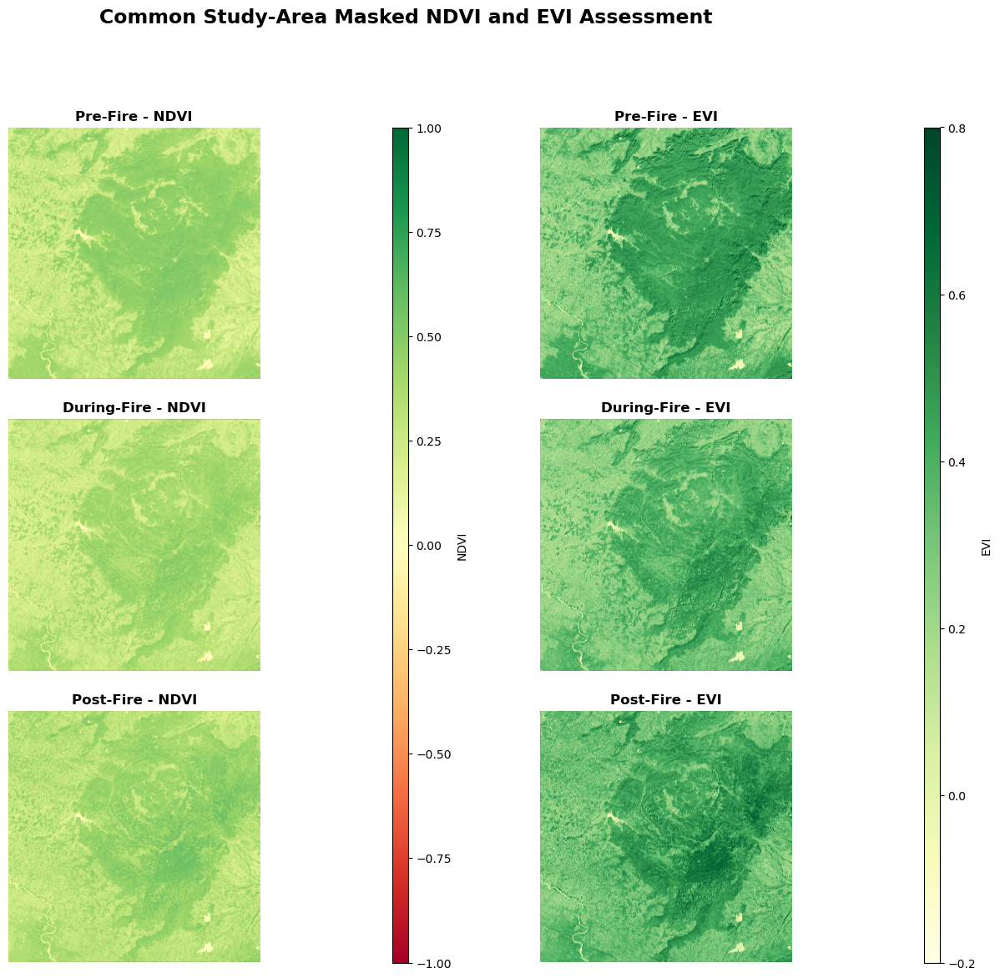

In [29]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(16, 13))

gs = fig.add_gridspec(
    3, 4,
    width_ratios=[1, 0.035, 1, 0.035],
    hspace=0.16,
    wspace=0.12
)

phases = ["Pre-Fire", "During-Fire", "Post-Fire"]

axes_ndvi = []
axes_evi = []

for i, phase in enumerate(phases):

    ax1 = fig.add_subplot(gs[i, 0])
    ax2 = fig.add_subplot(gs[i, 2])

    axes_ndvi.append(ax1)
    axes_evi.append(ax2)

    im1 = ax1.imshow(
        ndvi_results[phase],
        cmap="RdYlGn",
        vmin=-1,
        vmax=1
    )

    im2 = ax2.imshow(
        evi_results[phase],
        cmap="YlGn",
        vmin=-0.2,
        vmax=0.8
    )

    ax1.set_title(
        f"{phase} - NDVI",
        fontsize=12,
        fontweight="bold"
    )

    ax2.set_title(
        f"{phase} - EVI",
        fontsize=12,
        fontweight="bold"
    )

    ax1.axis("off")
    ax2.axis("off")

# Dedicated colour bars
cax1 = fig.add_subplot(gs[:, 1])
cax2 = fig.add_subplot(gs[:, 3])

fig.colorbar(im1, cax=cax1, label="NDVI")
fig.colorbar(im2, cax=cax2, label="EVI")

fig.suptitle(
    "Common Study-Area Masked NDVI and EVI Assessment",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

plt.savefig(
    "Fire_Project/NDVI_EVI_Final_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
#Calculate NBR for all three phases
nbr_results = {}
nbr_metadata = {}
nbr_masks = {}

for phase in ["Pre-Fire", "During-Fire", "Post-Fire"]:

    print(f"\nProcessing {phase}...")

    # Read existing B8
    with rasterio.open(paths[phase]) as src:

        nir = src.read(3).astype(np.float32)

        nir_valid = src.read_masks(3) > 0

        meta = src.meta.copy()

        transform = src.transform
        crs = src.crs

        height = src.height
        width = src.width

    # Read separate B12
    with rasterio.open(b12_paths[phase]) as swir_src:

        swir_native = swir_src.read(1).astype(np.float32)

        swir_native_valid = (
            swir_src.read_masks(1) > 0
        )

        swir = np.full(
            (height, width),
            np.nan,
            dtype=np.float32
        )

        # Align B12 with B8
        reproject(
            source=swir_native,
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            src_nodata=swir_src.nodata,
            dst_transform=transform,
            dst_crs=crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

        swir_valid = np.zeros(
            (height, width),
            dtype=np.uint8
        )

        reproject(
            source=swir_native_valid.astype(np.uint8),
            destination=swir_valid,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=transform,
            dst_crs=crs,
            resampling=Resampling.nearest
        )

    # Scale reflectance
    nir = nir / 10000.0
    swir = swir / 10000.0

    # Study-area masking
    projected_boundary = study_area.to_crs(crs)

    geometries = [
        geom.__geo_interface__
        for geom in projected_boundary.geometry
        if geom is not None and not geom.is_empty
    ]

    area_mask = geometry_mask(
        geometries,
        out_shape=(height, width),
        transform=transform,
        invert=True
    )

    # Valid pixels
    valid = (
        area_mask &
        nir_valid &
        (swir_valid > 0) &
        np.isfinite(nir) &
        np.isfinite(swir) &
        ((nir + swir) > 0)
    )

    # NBR calculation
    nbr = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    nbr[valid] = (
        (nir[valid] - swir[valid]) /
        (nir[valid] + swir[valid])
    )

    nbr[~np.isfinite(nbr)] = np.nan

    # Save results
    nbr_results[phase] = nbr
    nbr_masks[phase] = np.isfinite(nbr)
    nbr_metadata[phase] = meta

    print("Valid pixels:", np.count_nonzero(valid))
    print("Mean NBR:", np.nanmean(nbr))
    print("Minimum NBR:", np.nanmin(nbr))
    print("Maximum NBR:", np.nanmax(nbr))

print("\nAll three NBR calculations completed!")


Processing Pre-Fire...


RasterioIOError: Fire_Project/B12_PreFire.tif: No such file or directory

In [34]:
import os
import rasterio

print("FILES AVAILABLE IN FIRE_PROJECT\n")

for root, dirs, files in os.walk("Fire_Project"):

    for file in files:

        if file.lower().endswith((".tif", ".tiff")):

            path = os.path.join(root, file)

            print("\nFile:", path)

            try:
                with rasterio.open(path) as src:

                    print("Bands:", src.count)
                    print("Dimensions:", src.width, src.height)
                    print("Descriptions:", src.descriptions)

                    for i in range(1, src.count + 1):
                        print(
                            f"Band {i}:",
                            src.tags(i)
                        )

            except Exception as e:
                print("Error:", e)

FILES AVAILABLE IN FIRE_PROJECT


File: Fire_Project/S2_DuringFire.tif
Bands: 4
Dimensions: 7793 7798
Descriptions: ('B2', 'B4', 'B8', 'B11')
Band 1: {}
Band 2: {}
Band 3: {}
Band 4: {}

File: Fire_Project/LST_PostFire_2025.tif
Bands: 1
Dimensions: 2599 2600
Descriptions: ('ST_B10',)
Band 1: {'STATISTICS_APPROXIMATE': 'YES', 'STATISTICS_MAXIMUM': '47443', 'STATISTICS_MEAN': '45109.414775512', 'STATISTICS_MINIMUM': '43271', 'STATISTICS_STDDEV': '841.04083561347', 'STATISTICS_VALID_PERCENT': '59.95'}

File: Fire_Project/EVI_PreFire.tif
Bands: 1
Dimensions: 7793 7798
Descriptions: (None,)
Band 1: {}

File: Fire_Project/BRI_Post-Fire.tif
Bands: 1
Dimensions: 7793 7798
Descriptions: (None,)
Band 1: {}

File: Fire_Project/dNDVI_During.tif
Bands: 1
Dimensions: 7793 7794
Descriptions: (None,)
Band 1: {}

File: Fire_Project/S2_PostFire.tif
Bands: 4
Dimensions: 7793 7798
Descriptions: ('B2', 'B4', 'B8', 'B11')
Band 1: {}
Band 2: {}
Band 3: {}
Band 4: {}

File: Fire_Project/NDMI_Post-Fire.tif
Ban

In [35]:
print("Existing BRI variables:")

print("Available variables:",
      [v for v in globals() if "bri" in v.lower()])

print("\nSatellite image paths:")
print(s2_files)

Existing BRI variables:
Available variables: []

Satellite image paths:
{'Pre-Fire': 'Fire_Project/S2_PreFire.tif', 'During-Fire': 'Fire_Project/S2_DuringFire.tif', 'Post-Fire': 'Fire_Project/S2_PostFire.tif'}


In [36]:
import os
import rasterio

print("SEARCHING FOR B12 FILES...\n")

search_directory = os.getcwd()

b12_files = []

for root, dirs, files in os.walk(search_directory):

    for file in files:

        if file.lower().endswith((".tif", ".tiff")):

            path = os.path.join(root, file)

            try:
                with rasterio.open(path) as src:

                    descriptions = [
                        str(x).upper()
                        for x in src.descriptions
                    ]

                    if "B12" in file.upper() or "B12" in descriptions:

                        b12_files.append(path)

                        print("FOUND:", path)
                        print("Bands:", src.count)
                        print("Descriptions:", src.descriptions)
                        print("Dimensions:", src.width, src.height)

            except Exception:
                pass

print("\nTOTAL B12 FILES FOUND:", len(b12_files))

SEARCHING FOR B12 FILES...


TOTAL B12 FILES FOUND: 0


In [37]:
import rasterio

bri_path = "Fire_Project/BRI_Post-Fire.tif"

with rasterio.open(bri_path) as src:

    print("BRI RASTER INFORMATION")
    print("Dimensions:", src.width, src.height)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("NoData:", src.nodata)
    print("Tags:", src.tags())

BRI RASTER INFORMATION
Dimensions: 7793 7798
CRS: EPSG:4326
Transform: | 0.00, 0.00, 85.90|
| 0.00,-0.00, 22.10|
| 0.00, 0.00, 1.00|
NoData: None
Tags: {'AREA_OR_POINT': 'Area'}


BRI FILES SELECTED
Pre-Fire : Fire_Project/BRI_Pre-Fire.tif
During-Fire : Fire_Project/BRI_During-Fire.tif
Post-Fire : Fire_Project/BRI_Post-Fire.tif
Pre-Fire: Mean BRI = 0.08989
During-Fire: Mean BRI = 0.01722
Post-Fire: Mean BRI = 0.04089

Common valid pixels: 60755527

BRI CHANGE STATISTICS
During-Fire mean change: 0.0726726
Post-Fire mean change: 0.04900668

RELATIVE IMPACT THRESHOLDS
Low: 0.03651276230812073
Moderate: 0.07505408674478531
High: 0.12294042110443115

BURN IMPACT AREA STATISTICS


,Severity Class,Pixel Count,Area (Hectares),Area (km2),Percentage (%)
0,No Positive Change,16896061,156147.5592,1561.4756,27.8099
1,Low Impact,10964869,101344.0233,1013.4402,18.0475
2,Moderate Impact,10964865,101350.9192,1013.5092,18.0475
3,High Impact,10964866,101352.3416,1013.5234,18.0475
4,Very High Impact,10964866,101358.0648,1013.5806,18.0475


/var/folders/w8/b8zffph95bb14s2zc6dgzfpm0000gn/T/ipykernel_14041/3469021851.py:426: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


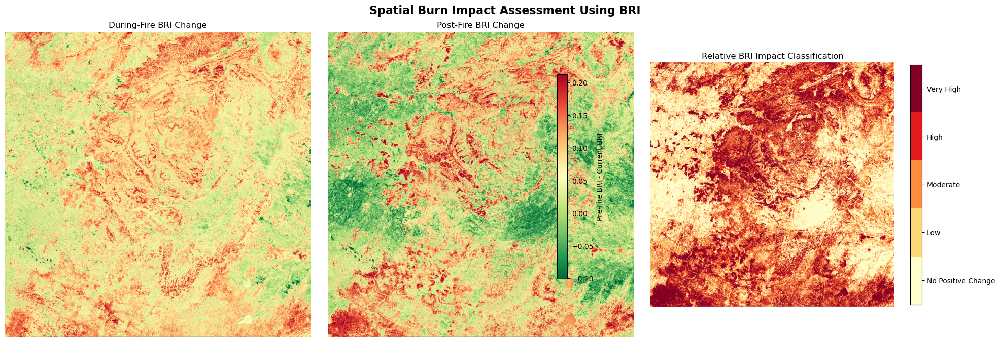

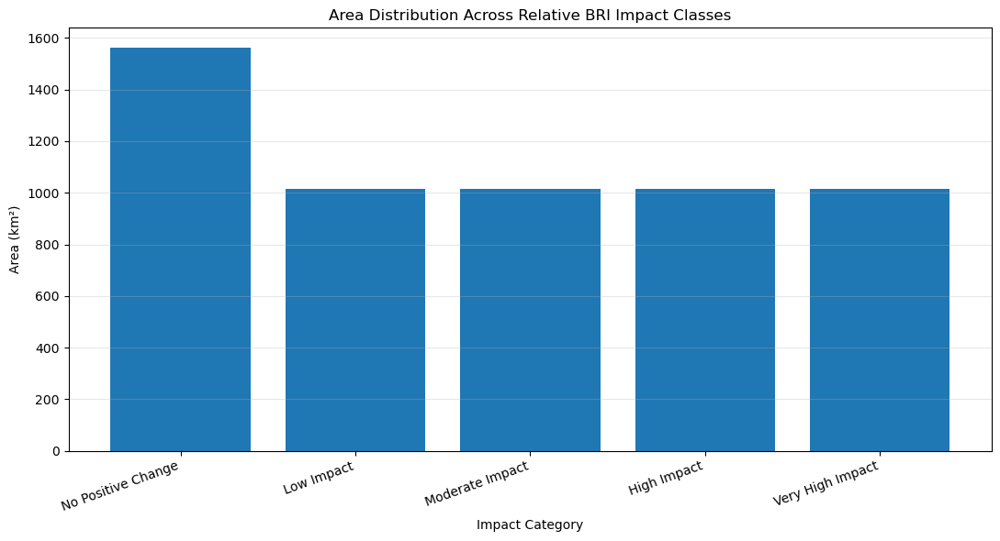


BRI SPATIAL IMPACT ANALYSIS COMPLETED
Output directory: Fire_Project/Burn_Severity_Analysis
Generated:
1. dBRI_During.tif
2. dBRI_Post.tif
3. BRI_Impact_Classification.tif
4. BRI_Impact_Maps.png
5. BRI_Impact_Area_Statistics.png
6. BRI_Impact_Area_Statistics.csv


In [38]:

# ============================================================
# SPATIAL BURN IMPACT CLASSIFICATION AND AREA ESTIMATION
# Using Existing BRI Rasters
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pyproj import CRS, Geod

# ------------------------------------------------------------
# STEP 1: FIND EXISTING BRI FILES
# ------------------------------------------------------------

output_dir = "Fire_Project/Burn_Severity_Analysis"
os.makedirs(output_dir, exist_ok=True)

all_tifs = glob.glob("Fire_Project/**/*.tif", recursive=True)

bri_files = {}

for phase, keywords in {
    "Pre-Fire": ["pre"],
    "During-Fire": ["during"],
    "Post-Fire": ["post"]
}.items():

    matches = [
        f for f in all_tifs
        if "bri" in os.path.basename(f).lower()
        and any(k in os.path.basename(f).lower() for k in keywords)
    ]

    if len(matches) == 1:
        bri_files[phase] = matches[0]
    elif len(matches) > 1:
        raise ValueError(
            f"Multiple BRI files found for {phase}: {matches}. "
            "Select the correct file manually."
        )
    else:
        raise FileNotFoundError(
            f"BRI file missing for {phase}. "
            f"Available BRI files: "
            f"{[f for f in all_tifs if 'bri' in f.lower()]}"
        )

print("BRI FILES SELECTED")

for phase, path in bri_files.items():
    print(phase, ":", path)


# ------------------------------------------------------------
# STEP 2: LOAD BRI RASTERS
# ------------------------------------------------------------

bri_data = {}
reference_profile = None
reference_transform = None
reference_crs = None

for phase, path in bri_files.items():

    with rasterio.open(path) as src:

        data = src.read(1).astype(np.float32)

        valid = (
            (src.read_masks(1) > 0) &
            np.isfinite(data) &
            (data >= -1.05) &
            (data <= 1.05)
        )

        data[~valid] = np.nan

        if reference_profile is None:
            reference_profile = src.profile.copy()
            reference_transform = src.transform
            reference_crs = src.crs
            reference_shape = data.shape

        else:
            if (
                data.shape != reference_shape or
                src.transform != reference_transform or
                src.crs != reference_crs
            ):
                raise ValueError(
                    f"{phase} BRI raster does not match "
                    "the reference raster grid. Align rasters first."
                )

        bri_data[phase] = data

        print(
            f"{phase}: Mean BRI = "
            f"{np.nanmean(data):.5f}"
        )


# ------------------------------------------------------------
# STEP 3: COMMON VALID PIXEL MASK
# ------------------------------------------------------------

common_mask = np.ones(reference_shape, dtype=bool)

for phase in bri_data:

    common_mask &= np.isfinite(bri_data[phase])

print("\nCommon valid pixels:", np.sum(common_mask))

if np.sum(common_mask) == 0:
    raise ValueError("No common valid pixels found.")


# ------------------------------------------------------------
# STEP 4: MULTI-TEMPORAL BRI DIFFERENCING
# ------------------------------------------------------------

pre = bri_data["Pre-Fire"]
during = bri_data["During-Fire"]
post = bri_data["Post-Fire"]

# Positive values indicate a decrease in BRI
dbri_during = pre - during
dbri_post = pre - post

dbri_during[~common_mask] = np.nan
dbri_post[~common_mask] = np.nan

print("\nBRI CHANGE STATISTICS")

print("During-Fire mean change:",
      np.nanmean(dbri_during))

print("Post-Fire mean change:",
      np.nanmean(dbri_post))


# ------------------------------------------------------------
# STEP 5: DATA-DRIVEN SEVERITY THRESHOLDS
# ------------------------------------------------------------

positive_changes = dbri_post[
    common_mask & (dbri_post > 0)
]

if len(positive_changes) == 0:
    raise ValueError(
        "No positive post-fire BRI changes found. "
        "Check the BRI formula and temporal data."
    )

q25, q50, q75 = np.percentile(
    positive_changes,
    [25, 50, 75]
)

print("\nRELATIVE IMPACT THRESHOLDS")

print("Low:", q25)
print("Moderate:", q50)
print("High:", q75)


# ------------------------------------------------------------
# STEP 6: CLASSIFY BURN IMPACT
# ------------------------------------------------------------

# 0 = No positive change
# 1 = Low relative impact
# 2 = Moderate relative impact
# 3 = High relative impact
# 4 = Very high relative impact
# 255 = NoData

severity = np.full(
    reference_shape,
    255,
    dtype=np.uint8
)

severity[common_mask & (dbri_post <= 0)] = 0

severity[
    common_mask &
    (dbri_post > 0) &
    (dbri_post <= q25)
] = 1

severity[
    common_mask &
    (dbri_post > q25) &
    (dbri_post <= q50)
] = 2

severity[
    common_mask &
    (dbri_post > q50) &
    (dbri_post <= q75)
] = 3

severity[
    common_mask &
    (dbri_post > q75)
] = 4

class_names = {
    0: "No Positive Change",
    1: "Low Impact",
    2: "Moderate Impact",
    3: "High Impact",
    4: "Very High Impact"
}


# ------------------------------------------------------------
# STEP 7: CALCULATE AREA IN HECTARES AND KM2
# ------------------------------------------------------------

# Correctly account for geographic pixel area
# instead of treating square degrees as square metres.

crs_obj = CRS.from_user_input(reference_crs)

if crs_obj.is_geographic:

    geod = crs_obj.get_geod()

    pixel_areas = []

    for row in range(reference_shape[0]):

        corners = [
            reference_transform * (0, row),
            reference_transform * (1, row),
            reference_transform * (1, row + 1),
            reference_transform * (0, row + 1)
        ]

        xs = [p[0] for p in corners]
        ys = [p[1] for p in corners]

        area, _ = geod.polygon_area_perimeter(xs, ys)

        pixel_areas.append(abs(area))

    pixel_areas = np.asarray(pixel_areas)

else:

    pixel_area = abs(
        reference_transform.a * reference_transform.e -
        reference_transform.b * reference_transform.d
    )

    # Convert projected square units to square metres
    factor = crs_obj.axis_info[0].unit_conversion_factor
    pixel_area *= factor ** 2

    pixel_areas = np.full(
        reference_shape[0],
        pixel_area
    )

area_results = []

for class_id, class_name in class_names.items():

    class_mask = severity == class_id

    pixel_count = int(np.sum(class_mask))

    area_m2 = np.sum(
        np.sum(class_mask, axis=1) * pixel_areas
    )

    area_ha = area_m2 / 10000
    area_km2 = area_m2 / 1000000

    percentage = (
        pixel_count / np.sum(common_mask)
    ) * 100

    area_results.append({
        "Severity Class": class_name,
        "Pixel Count": pixel_count,
        "Area (Hectares)": area_ha,
        "Area (km2)": area_km2,
        "Percentage (%)": percentage
    })

area_df = pd.DataFrame(area_results)

print("\nBURN IMPACT AREA STATISTICS")

display(area_df.round(4))


# ------------------------------------------------------------
# STEP 8: SAVE OUTPUT RASTERS
# ------------------------------------------------------------

profile = reference_profile.copy()

profile.update(
    dtype="float32",
    count=1,
    nodata=-9999
)

for name, data in {
    "dBRI_During": dbri_during,
    "dBRI_Post": dbri_post
}.items():

    output = np.where(
        np.isfinite(data),
        data,
        -9999
    ).astype(np.float32)

    with rasterio.open(
        f"{output_dir}/{name}.tif",
        "w",
        **profile
    ) as dst:

        dst.write(output, 1)


class_profile = reference_profile.copy()

class_profile.update(
    dtype="uint8",
    count=1,
    nodata=255
)

with rasterio.open(
    f"{output_dir}/BRI_Impact_Classification.tif",
    "w",
    **class_profile
) as dst:

    dst.write(severity, 1)


# ------------------------------------------------------------
# STEP 9: GENERATE IMPACT MAPS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 7)
)

im1 = axes[0].imshow(
    dbri_during,
    cmap="RdYlGn_r",
    vmin=np.nanpercentile(dbri_post, 2),
    vmax=np.nanpercentile(dbri_post, 98)
)

axes[0].set_title("During-Fire BRI Change")
axes[0].axis("off")

im2 = axes[1].imshow(
    dbri_post,
    cmap="RdYlGn_r",
    vmin=np.nanpercentile(dbri_post, 2),
    vmax=np.nanpercentile(dbri_post, 98)
)

axes[1].set_title("Post-Fire BRI Change")
axes[1].axis("off")

cmap = plt.get_cmap("YlOrRd", 5)

im3 = axes[2].imshow(
    np.ma.masked_equal(severity, 255),
    cmap=cmap,
    vmin=-0.5,
    vmax=4.5
)

axes[2].set_title("Relative BRI Impact Classification")
axes[2].axis("off")

cbar1 = fig.colorbar(
    im1,
    ax=axes[:2].tolist(),
    shrink=0.75
)

cbar1.set_label("Pre-Fire BRI - Current BRI")

cbar2 = fig.colorbar(
    im3,
    ax=axes[2],
    ticks=range(5),
    shrink=0.75
)

cbar2.ax.set_yticklabels([
    "No Positive Change",
    "Low",
    "Moderate",
    "High",
    "Very High"
])

fig.suptitle(
    "Spatial Burn Impact Assessment Using BRI",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/BRI_Impact_Maps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# STEP 10: GENERATE AREA STATISTICS GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    area_df["Severity Class"],
    area_df["Area (km2)"]
)

plt.title(
    "Area Distribution Across Relative BRI Impact Classes"
)

plt.xlabel("Impact Category")
plt.ylabel("Area (km²)")

plt.xticks(rotation=20, ha="right")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    f"{output_dir}/BRI_Impact_Area_Statistics.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# SAVE STATISTICS
# ------------------------------------------------------------

area_df.to_csv(
    f"{output_dir}/BRI_Impact_Area_Statistics.csv",
    index=False
)

print("\n==========================================")
print("BRI SPATIAL IMPACT ANALYSIS COMPLETED")
print("==========================================")

print("Output directory:", output_dir)

print("Generated:")
print("1. dBRI_During.tif")
print("2. dBRI_Post.tif")
print("3. BRI_Impact_Classification.tif")
print("4. BRI_Impact_Maps.png")
print("5. BRI_Impact_Area_Statistics.png")
print("6. BRI_Impact_Area_Statistics.csv")


The multi-temporal BRI analysis revealed a substantial reduction in the mean spectral response during the fire phase, decreasing from 0.08989 before the fire to 0.01722 during the fire. Following the fire, the mean value increased to 0.04089, indicating a partial return towards pre-fire spectral conditions. Relative impact classification further divided the positive BRI changes into four quartile-based categories, with approximately 72.19% of common valid pixels exhibiting positive changes.

Spatial Ecological Vulnerability and Post-Fire Restoration Priority Assessment
(The objective is to combine your existing satellite analysis to identify which parts of the Similipal forest need restoration most urgently.)

In [40]:
import os
import json
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from pyproj import CRS

# Your existing Sentinel-2 file paths
s2_paths = {
    "Pre-Fire": s2_files["Pre-Fire"],
    "During-Fire": s2_files["During-Fire"],
    "Post-Fire": s2_files["Post-Fire"]
}

# Study area boundary
boundary_path = (
    boundary_path if "boundary_path" in globals()
    else "/Users/pragya/Documents/Similipal_Project/Fire_Project/similipal_boundary.geojson"
)

# Base directory
BASE_DIR = os.path.dirname(s2_paths["Post-Fire"])

# LST files
lst_paths = {
    "Pre-Fire": os.path.join(BASE_DIR, "LST_PreFire_Relative.tif"),
    "During-Fire": os.path.join(BASE_DIR, "LST_DuringFire_Relative.tif"),
    "Post-Fire": os.path.join(BASE_DIR, "LST_PostFire_Relative.tif")
}

# Output directory
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "Ecological_Vulnerability_Analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Check input files
print("SENTINEL-2 FILES")

for phase, path in s2_paths.items():
    print(phase, ":", os.path.exists(path), path)

print("\nLST FILES")

for phase, path in lst_paths.items():
    print(phase, ":", os.path.exists(path), path)

print("\nBoundary:", os.path.exists(boundary_path))
print("Output directory:", OUTPUT_DIR)

SENTINEL-2 FILES
Pre-Fire : True Fire_Project/S2_PreFire.tif
During-Fire : True Fire_Project/S2_DuringFire.tif
Post-Fire : True Fire_Project/S2_PostFire.tif

LST FILES
Pre-Fire : True Fire_Project/LST_PreFire_Relative.tif
During-Fire : True Fire_Project/LST_DuringFire_Relative.tif
Post-Fire : True Fire_Project/LST_PostFire_Relative.tif

Boundary: True
Output directory: Fire_Project/Ecological_Vulnerability_Analysis


In [41]:
# Load the study-area boundary
study_area = gpd.read_file(boundary_path)

# Use the post-fire Sentinel-2 raster as reference
with rasterio.open(s2_paths["Post-Fire"]) as ref:
    reference_profile = ref.profile.copy()
    reference_transform = ref.transform
    reference_crs = ref.crs
    reference_shape = (ref.height, ref.width)

# Project boundary into the reference raster CRS
study_area = study_area.to_crs(reference_crs)

geometries = [
    geom.__geo_interface__
    for geom in study_area.geometry
    if geom is not None and not geom.is_empty
]

# Pixels inside the Similipal boundary
area_mask = geometry_mask(
    geometries,
    out_shape=reference_shape,
    transform=reference_transform,
    invert=True
)

print("Reference grid:", reference_shape)
print("Reference CRS:", reference_crs)
print("Pixels inside study area:", np.sum(area_mask))

Reference grid: (7798, 7793)
Reference CRS: EPSG:4326
Pixels inside study area: 60723056


In [42]:
def align_band_to_reference(
    source_path,
    band_number,
    reference_shape,
    reference_transform,
    reference_crs,
    resampling=Resampling.bilinear
):
    with rasterio.open(source_path) as src:

        source = src.read(band_number).astype(np.float32)

        source_valid = src.read_masks(band_number) > 0

        source[~source_valid] = np.nan

        destination = np.full(
            reference_shape,
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=reference_transform,
            dst_crs=reference_crs,
            dst_nodata=np.nan,
            resampling=resampling
        )

    return destination


ndvi_maps = {}
evi_maps = {}
ndmi_maps = {}
valid_masks = {}

for phase, image_path in s2_paths.items():

    print("\nProcessing:", phase)

    # Band order follows your notebook:
    # Band 1 = B2 Blue
    # Band 2 = B4 Red
    # Band 3 = B8 NIR
    # Band 4 = B11 SWIR

    blue = align_band_to_reference(
        image_path, 1,
        reference_shape,
        reference_transform,
        reference_crs
    ) / 10000.0

    red = align_band_to_reference(
        image_path, 2,
        reference_shape,
        reference_transform,
        reference_crs
    ) / 10000.0

    nir = align_band_to_reference(
        image_path, 3,
        reference_shape,
        reference_transform,
        reference_crs
    ) / 10000.0

    swir = align_band_to_reference(
        image_path, 4,
        reference_shape,
        reference_transform,
        reference_crs
    ) / 10000.0

    # NDVI
    ndvi_den = nir + red

    ndvi = np.full(reference_shape, np.nan, dtype=np.float32)

    valid_ndvi = (
        np.isfinite(nir) &
        np.isfinite(red) &
        (ndvi_den > 0)
    )

    ndvi[valid_ndvi] = (
        (nir[valid_ndvi] - red[valid_ndvi]) /
        ndvi_den[valid_ndvi]
    )

    # EVI
    evi_den = nir + 6 * red - 7.5 * blue + 1

    evi = np.full(reference_shape, np.nan, dtype=np.float32)

    valid_evi = (
        np.isfinite(blue) &
        np.isfinite(red) &
        np.isfinite(nir) &
        (evi_den > 0.01)
    )

    evi[valid_evi] = (
        2.5 *
        (nir[valid_evi] - red[valid_evi]) /
        evi_den[valid_evi]
    )

    # NDMI = (NIR - SWIR1) / (NIR + SWIR1)
    ndmi_den = nir + swir

    ndmi = np.full(reference_shape, np.nan, dtype=np.float32)

    valid_ndmi = (
        np.isfinite(nir) &
        np.isfinite(swir) &
        (ndmi_den > 0)
    )

    ndmi[valid_ndmi] = (
        (nir[valid_ndmi] - swir[valid_ndmi]) /
        ndmi_den[valid_ndmi]
    )

    # Apply study-area and valid-pixel masks
    valid = (
        area_mask &
        valid_ndvi &
        valid_evi &
        valid_ndmi &
        np.isfinite(ndvi) &
        np.isfinite(evi) &
        np.isfinite(ndmi) &
        (np.abs(evi) <= 1.5) &
        (ndvi >= -1) &
        (ndvi <= 1) &
        (ndmi >= -1) &
        (ndmi <= 1)
    )

    ndvi[~valid] = np.nan
    evi[~valid] = np.nan
    ndmi[~valid] = np.nan

    ndvi_maps[phase] = ndvi
    evi_maps[phase] = evi
    ndmi_maps[phase] = ndmi
    valid_masks[phase] = valid

    print("Valid pixels:", np.sum(valid))
    print("Mean NDVI:", np.nanmean(ndvi))
    print("Mean EVI:", np.nanmean(evi))
    print("Mean NDMI:", np.nanmean(ndmi))

print("\nAll three indicators calculated.")


Processing: Pre-Fire
Valid pixels: 60708757
Mean NDVI: 0.3514815
Mean EVI: 0.3694548
Mean NDMI: 0.08993011

Processing: During-Fire
Valid pixels: 60708765
Mean NDVI: 0.32303566
Mean EVI: 0.32814905
Mean NDMI: 0.01722576

Processing: Post-Fire
Valid pixels: 60708718
Mean NDVI: 0.36817342
Mean EVI: 0.38995883
Mean NDMI: 0.040897693

All three indicators calculated.


In [43]:
lst_maps = {}

for phase, lst_path in lst_paths.items():

    if not os.path.exists(lst_path):
        raise FileNotFoundError(
            f"Missing LST raster for {phase}: {lst_path}"
        )

    with rasterio.open(lst_path) as src:

        lst_source = src.read(1).astype(np.float32)

        lst_source_valid = (
            (src.read_masks(1) > 0) &
            np.isfinite(lst_source)
        )

        if src.nodata is not None:
            lst_source_valid &= (
                lst_source != src.nodata
            )

        lst_source[~lst_source_valid] = np.nan

        lst_aligned = np.full(
            reference_shape,
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=lst_source,
            destination=lst_aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=reference_transform,
            dst_crs=reference_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    lst_aligned[~area_mask] = np.nan

    lst_maps[phase] = lst_aligned

    print(
        phase,
        "relative LST mean:",
        np.nanmean(lst_aligned)
    )

# Relative thermal change
thermal_change = (
    lst_maps["Post-Fire"] -
    lst_maps["Pre-Fire"]
)

print("\nMean relative thermal change:",
      np.nanmean(thermal_change))

Pre-Fire relative LST mean: 43355.73
During-Fire relative LST mean: 45776.246
Post-Fire relative LST mean: 45078.625

Mean relative thermal change: 1699.4668


In [44]:
# Vegetation loss
vegetation_loss = (
    evi_maps["Pre-Fire"] -
    evi_maps["Post-Fire"]
)

# Moisture loss
moisture_loss = (
    ndmi_maps["Pre-Fire"] -
    ndmi_maps["Post-Fire"]
)

# Only retain positive degradation
vegetation_loss = np.maximum(
    vegetation_loss,
    0
)

moisture_loss = np.maximum(
    moisture_loss,
    0
)

# Positive thermal change indicates relative warming
thermal_stress = np.maximum(
    thermal_change,
    0
)

print("Mean vegetation loss:",
      np.nanmean(vegetation_loss))

print("Mean moisture loss:",
      np.nanmean(moisture_loss))

print("Mean positive thermal change:",
      np.nanmean(thermal_stress))

Mean vegetation loss: 0.02386775
Mean moisture loss: 0.060999397
Mean positive thermal change: 1703.9518


In [45]:
def normalize_indicator(data, mask, name):

    values = data[mask & np.isfinite(data)]

    if len(values) == 0:
        raise ValueError(
            f"No valid values available for {name}"
        )

    lower = np.percentile(values, 5)
    upper = np.percentile(values, 95)

    if upper <= lower:
        raise ValueError(
            f"Cannot normalize {name}: insufficient variation."
        )

    normalized = np.full(
        data.shape,
        np.nan,
        dtype=np.float32
    )

    normalized[mask] = np.clip(
        (data[mask] - lower) / (upper - lower),
        0,
        1
    )

    print(
        name,
        "normalization limits:",
        round(float(lower), 5),
        "to",
        round(float(upper), 5)
    )

    return normalized


# Common valid pixels across the required inputs
common_mask = (
    area_mask &
    np.isfinite(vegetation_loss) &
    np.isfinite(moisture_loss) &
    np.isfinite(thermal_stress) &
    np.isfinite(lst_maps["Pre-Fire"]) &
    np.isfinite(lst_maps["Post-Fire"])
)

print("Common valid pixels:", np.sum(common_mask))

# Normalize each component
vegetation_score = normalize_indicator(
    vegetation_loss,
    common_mask,
    "Vegetation degradation"
)

moisture_score = normalize_indicator(
    moisture_loss,
    common_mask,
    "Moisture degradation"
)

thermal_score = normalize_indicator(
    thermal_stress,
    common_mask,
    "Relative thermal stress"
)

Common valid pixels: 37714672
Vegetation degradation normalization limits: 0.0 to 0.11713
Moisture degradation normalization limits: 0.0 to 0.19013
Relative thermal stress normalization limits: 216.27734 to 3137.0


In [46]:
# Initial exploratory weights
W_VEGETATION = 0.40
W_MOISTURE = 0.30
W_THERMAL = 0.30

assert np.isclose(
    W_VEGETATION + W_MOISTURE + W_THERMAL,
    1.0
)

# Calculate composite score
ecological_vulnerability = (
    W_VEGETATION * vegetation_score +
    W_MOISTURE * moisture_score +
    W_THERMAL * thermal_score
)

ecological_vulnerability[~common_mask] = np.nan

print("Ecological Vulnerability Score")
print("Mean:", np.nanmean(ecological_vulnerability))
print("Minimum:", np.nanmin(ecological_vulnerability))
print("Maximum:", np.nanmax(ecological_vulnerability))

Ecological Vulnerability Score
Mean: 0.32731345
Minimum: 0.0
Maximum: 1.0


In [47]:
# Priority class codes
# 1 = Low
# 2 = Moderate
# 3 = High
# 4 = Very High
# 255 = NoData

priority_map = np.full(
    reference_shape,
    255,
    dtype=np.uint8
)

priority_map[
    common_mask &
    (ecological_vulnerability < 0.25)
] = 1

priority_map[
    common_mask &
    (ecological_vulnerability >= 0.25) &
    (ecological_vulnerability < 0.50)
] = 2

priority_map[
    common_mask &
    (ecological_vulnerability >= 0.50) &
    (ecological_vulnerability < 0.75)
] = 3

priority_map[
    common_mask &
    (ecological_vulnerability >= 0.75)
] = 4

priority_names = {
    1: "Low Priority",
    2: "Moderate Priority",
    3: "High Priority",
    4: "Very High Priority"
}

print("Restoration priority classification completed.")

Restoration priority classification completed.


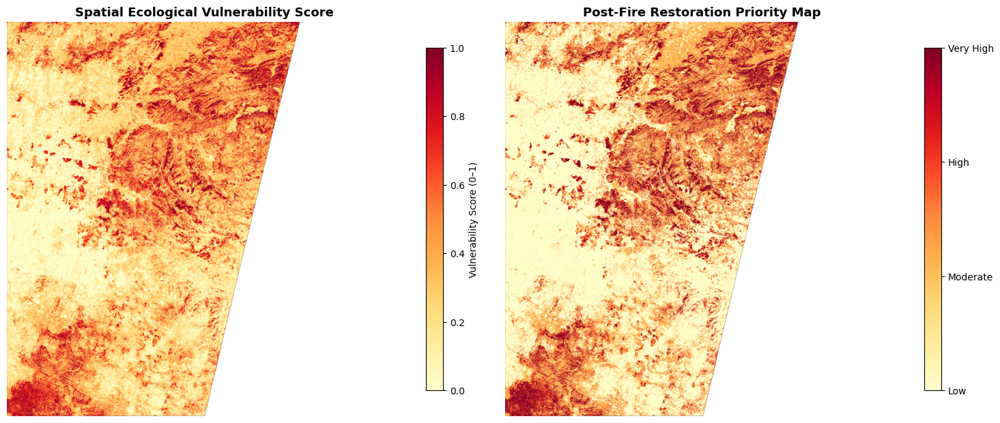

In [48]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7)
)

# Ecological vulnerability score
im1 = axes[0].imshow(
    ecological_vulnerability,
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

axes[0].set_title(
    "Spatial Ecological Vulnerability Score",
    fontsize=13,
    fontweight="bold"
)

axes[0].axis("off")

cbar1 = fig.colorbar(
    im1,
    ax=axes[0],
    shrink=0.75
)

cbar1.set_label("Vulnerability Score (0–1)")


# Restoration priority map
priority_display = np.ma.masked_equal(
    priority_map,
    255
)

im2 = axes[1].imshow(
    priority_display,
    cmap="YlOrRd",
    vmin=1,
    vmax=4
)

axes[1].set_title(
    "Post-Fire Restoration Priority Map",
    fontsize=13,
    fontweight="bold"
)

axes[1].axis("off")

cbar2 = fig.colorbar(
    im2,
    ax=axes[1],
    ticks=[1, 2, 3, 4],
    shrink=0.75
)

cbar2.ax.set_yticklabels([
    "Low",
    "Moderate",
    "High",
    "Very High"
])

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Ecological_Vulnerability_Restoration_Priority.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
#Calculate the area under each restoration priority
# ============================================================
# AREA CALCULATION FOR GEOGRAPHIC CRS (EPSG:4326)
# ============================================================

import numpy as np
import pandas as pd
from pyproj import Geod

# Geodesic calculator
geod = Geod(ellps="WGS84")

# Get raster dimensions
height, width = priority_map.shape

# Store area for each priority class
priority_area = {}

# Priority class values:
# 1 = Low
# 2 = Moderate
# 3 = High
# 4 = Very High

priority_labels = {
    1: "Low",
    2: "Moderate",
    3: "High",
    4: "Very High"
}

# Calculate pixel area for each row
for class_value, class_name in priority_labels.items():

    total_area_m2 = 0.0

    for row in range(height):

        # Count pixels belonging to this class in this row
        pixel_count = np.count_nonzero(
            priority_map[row, :] == class_value
        )

        if pixel_count == 0:
            continue

        # Get geographic coordinates of pixel corners
        left, top = reference_transform * (0, row)
        right, bottom = reference_transform * (1, row + 1)

        # Calculate geodesic area of one pixel
        area, _ = geod.polygon_area_perimeter(
            [left, right, right, left],
            [top, top, bottom, bottom]
        )

        pixel_area_m2 = abs(area)

        total_area_m2 += pixel_count * pixel_area_m2

    priority_area[class_name] = {
        "Area (m²)": total_area_m2,
        "Area (hectares)": total_area_m2 / 10000,
        "Area (km²)": total_area_m2 / 1000000
    }

# Create results table
area_df = pd.DataFrame(priority_area).T

print("\nPOST-FIRE RESTORATION PRIORITY AREA")
display(area_df.round(3))

# Calculate total area
print(
    "\nTotal classified area (km²):",
    round(area_df["Area (km²)"].sum(), 3)
)




POST-FIRE RESTORATION PRIORITY AREA


,Area (m²),Area (hectares),Area (km²)
Low,1.638293e+09,163829.329,1638.293
Moderate,1.065567e+09,106556.659,1065.567
High,4.433135e+08,44331.346,443.313
Very High,3.381958e+08,33819.585,338.196



Total classified area (km²): 3485.369


In [51]:
def save_final_raster(data, filename, dtype="float32", nodata=-9999):

    output_path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    profile = reference_profile.copy()

    profile.update({
        "driver": "GTiff",
        "height": reference_shape[0],
        "width": reference_shape[1],
        "count": 1,
        "dtype": dtype,
        "nodata": nodata,
        "compress": "lzw"
    })

    if dtype == "uint8":

        output_data = np.where(
            data == 255,
            nodata,
            data
        ).astype(np.uint8)

    else:

        output_data = np.where(
            np.isfinite(data),
            data,
            nodata
        ).astype(np.float32)

    with rasterio.open(
        output_path,
        "w",
        **profile
    ) as dst:

        dst.write(output_data, 1)

    print("Saved:", output_path)


# Final composite products
save_final_raster(
    ecological_vulnerability,
    "Ecological_Vulnerability_Score.tif"
)

save_final_raster(
    priority_map,
    "Restoration_Priority_Classification.tif",
    dtype="uint8",
    nodata=255
)

# Individual normalized components
save_final_raster(
    vegetation_score,
    "Vegetation_Degradation_Score.tif"
)

save_final_raster(
    moisture_score,
    "Moisture_Degradation_Score.tif"
)

save_final_raster(
    thermal_score,
    "Relative_Thermal_Stress_Score.tif"
)

print("\nAll final raster outputs saved successfully!")

Saved: Fire_Project/Ecological_Vulnerability_Analysis/Ecological_Vulnerability_Score.tif
Saved: Fire_Project/Ecological_Vulnerability_Analysis/Restoration_Priority_Classification.tif
Saved: Fire_Project/Ecological_Vulnerability_Analysis/Vegetation_Degradation_Score.tif
Saved: Fire_Project/Ecological_Vulnerability_Analysis/Moisture_Degradation_Score.tif
Saved: Fire_Project/Ecological_Vulnerability_Analysis/Relative_Thermal_Stress_Score.tif

All final raster outputs saved successfully!


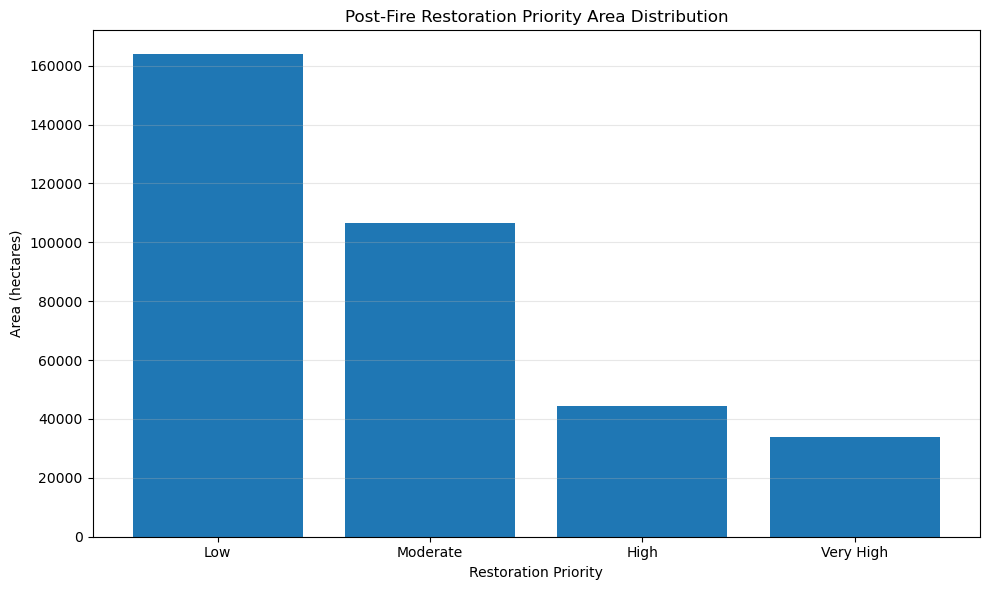

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    area_df.index,
    area_df["Area (hectares)"]
)

plt.title("Post-Fire Restoration Priority Area Distribution")
plt.xlabel("Restoration Priority")
plt.ylabel("Area (hectares)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [55]:
weight_scenarios = {
    "Equal Weights": (0.3333, 0.3333, 0.3334),
    "Vegetation Focus": (0.50, 0.25, 0.25),
    "Moisture Focus": (0.25, 0.50, 0.25),
    "Thermal Focus": (0.25, 0.25, 0.50),
    "Initial Model": (0.40, 0.30, 0.30)
}

sensitivity_results = []

for scenario, weights in weight_scenarios.items():

    w_veg, w_moist, w_thermal = weights

    score = (
        w_veg * vegetation_score +
        w_moist * moisture_score +
        w_thermal * thermal_score
    )

    score[~common_mask] = np.nan

    very_high = (
        common_mask &
        (score >= 0.75)
    )

    sensitivity_results.append({
        "Scenario": scenario,
        "Vegetation Weight": w_veg,
        "Moisture Weight": w_moist,
        "Thermal Weight": w_thermal,
        "Mean Vulnerability": np.nanmean(score),
        "Very High Priority Pixels": np.sum(very_high),
        "Very High Priority (%)": (
            np.sum(very_high) /
            np.sum(common_mask) * 100
        )
    })

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

print("WEIGHT SENSITIVITY ANALYSIS")

display(sensitivity_df.round(4))

sensitivity_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Weight_Sensitivity_Analysis.csv"
    ),
    index=False
)

WEIGHT SENSITIVITY ANALYSIS


,Scenario,Vegetation Weight,Moisture Weight,Thermal Weight,Mean Vulnerability,Very High Priority Pixels,Very High Priority (%)
0,Equal Weights,0.3333,0.3333,0.3334,0.3438,3740261,9.9173
1,Vegetation Focus,0.5000,0.2500,0.2500,0.3027,3573384,9.4748
2,Moisture Focus,0.2500,0.5000,0.2500,0.3439,4082012,10.8234
3,Thermal Focus,0.2500,0.2500,0.5000,0.3846,3868169,10.2564
4,Initial Model,0.4000,0.3000,0.3000,0.3273,3660755,9.7064


Assessment of Post-Fire Vegetation Condition Using the Modified Soil-Adjusted Vegetation Index (MSAVI).
(Helps assess vegetation where fire has exposed bare soil)

In [56]:

# ============================================================
# MSAVI ANALYSIS - PRE, DURING AND POST FIRE
# ============================================================

import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Store MSAVI results
msavi_results = {}
msavi_metadata = {}

phases = ["Pre-Fire", "During-Fire", "Post-Fire"]

for phase in phases:

    print(f"\nProcessing {phase}...")

    image_path = paths[phase]

    with rasterio.open(image_path) as src:

        # Extract Sentinel-2 bands
        red = src.read(2).astype(np.float32) / 10000.0
        nir = src.read(3).astype(np.float32) / 10000.0

        # Valid source pixels
        valid_mask = (
            (src.read_masks(2) > 0) &
            (src.read_masks(3) > 0) &
            np.isfinite(red) &
            np.isfinite(nir)
        )

        meta = src.meta.copy()

    # MSAVI calculation
    discriminant = (
        (2 * nir + 1) ** 2 -
        8 * (nir - red)
    )

    valid_mask &= (
        (discriminant >= 0) &
        ((nir + red) > 0)
    )

    msavi = np.full(
        nir.shape,
        np.nan,
        dtype=np.float32
    )

    msavi[valid_mask] = (
        2 * nir[valid_mask] + 1 -
        np.sqrt(discriminant[valid_mask])
    ) / 2

    # Store results
    msavi_results[phase] = msavi
    msavi_metadata[phase] = meta

    print("Valid pixels:", np.count_nonzero(np.isfinite(msavi)))
    print("Mean MSAVI:", np.nanmean(msavi))
    print("Minimum MSAVI:", np.nanmin(msavi))
    print("Maximum MSAVI:", np.nanmax(msavi))

print("\nMSAVI calculation completed!")



Processing Pre-Fire...
Valid pixels: 60733371
Mean MSAVI: 0.24573545
Minimum MSAVI: -0.24127853
Maximum MSAVI: 0.7023756

Processing During-Fire...
Valid pixels: 60733371
Mean MSAVI: 0.23015447
Minimum MSAVI: -0.24082673
Maximum MSAVI: 0.6188369

Processing Post-Fire...
Valid pixels: 60733371
Mean MSAVI: 0.27652243
Minimum MSAVI: -0.21876067
Maximum MSAVI: 0.64335907

MSAVI calculation completed!


/var/folders/w8/b8zffph95bb14s2zc6dgzfpm0000gn/T/ipykernel_14041/62580100.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


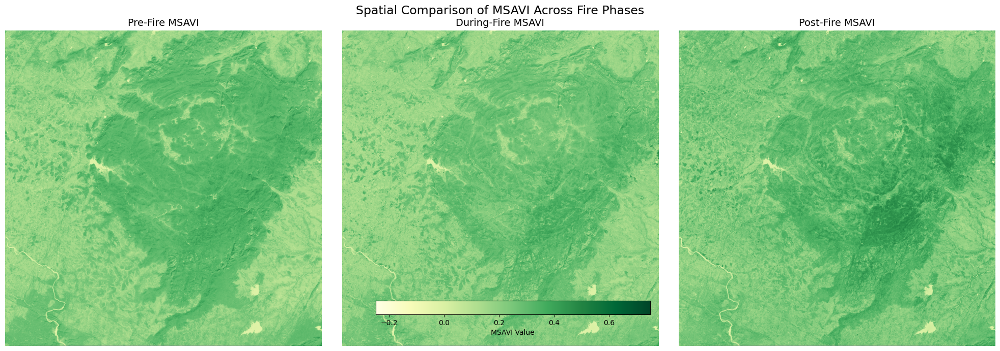

In [57]:

# ============================================================
# CELL 15: MSAVI SPATIAL VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

vmin = -0.25
vmax = 0.75

for ax, phase in zip(axes, phases):

    im = ax.imshow(
        msavi_results[phase],
        cmap="YlGn",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(f"{phase} MSAVI", fontsize=14)
    ax.axis("off")

cbar = fig.colorbar(
    im,
    ax=axes,
    orientation="horizontal",
    fraction=0.05,
    pad=0.08
)

cbar.set_label("MSAVI Value")

plt.suptitle(
    "Spatial Comparison of MSAVI Across Fire Phases",
    fontsize=17
)

plt.tight_layout()
plt.show()


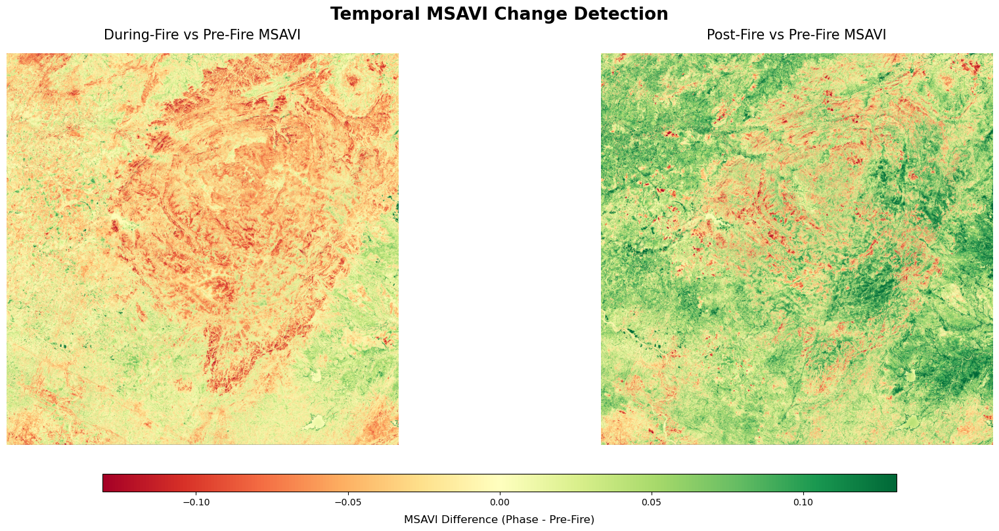

In [59]:

# ============================================================
# IMPROVED MSAVI CHANGE DETECTION VISUALIZATION
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    constrained_layout=True
)

# Common symmetric colour scale
limit = np.nanpercentile(
    np.abs(np.concatenate([
        during_change[common_mask],
        post_change[common_mask]
    ])),
    98
)

im1 = axes[0].imshow(
    during_change,
    cmap="RdYlGn",
    vmin=-limit,
    vmax=limit
)

axes[0].set_title(
    "During-Fire vs Pre-Fire MSAVI",
    fontsize=15,
    pad=15
)
axes[0].axis("off")

im2 = axes[1].imshow(
    post_change,
    cmap="RdYlGn",
    vmin=-limit,
    vmax=limit
)

axes[1].set_title(
    "Post-Fire vs Pre-Fire MSAVI",
    fontsize=15,
    pad=15
)
axes[1].axis("off")

# Separate horizontal colour bar below both maps
cbar = fig.colorbar(
    im2,
    ax=axes,
    orientation="horizontal",
    fraction=0.045,
    pad=0.07,
    aspect=45
)

cbar.set_label(
    "MSAVI Difference (Phase - Pre-Fire)",
    fontsize=12,
    labelpad=8
)

cbar.ax.tick_params(labelsize=10)

fig.suptitle(
    "Temporal MSAVI Change Detection",
    fontsize=19,
    fontweight="bold"
)

plt.show()


In [60]:

# ============================================================
# CELL 17: MSAVI CHANGE CATEGORY AND AREA STATISTICS
# ============================================================

threshold = 0.01

def calculate_change_statistics(change_map, mask, phase_name):

    values = change_map[mask]

    decrease = np.sum(values < -threshold)
    stable = np.sum(
        (values >= -threshold) & (values <= threshold)
    )
    increase = np.sum(values > threshold)

    total = len(values)

    results = {
        "Decrease": decrease,
        "No Significant Change": stable,
        "Increase": increase
    }

    print(f"\n{phase_name} MSAVI Change Distribution")
    print("-" * 45)

    for category, count in results.items():
        percentage = (count / total) * 100

        print(
            f"{category}: {count:,} pixels "
            f"({percentage:.2f}%)"
        )

    print("Total valid pixels:", f"{total:,}")
    print("Mean change:", f"{np.mean(values):.5f}")

    return results


during_stats = calculate_change_statistics(
    during_change,
    common_mask,
    "During-Fire vs Pre-Fire"
)

post_stats = calculate_change_statistics(
    post_change,
    common_mask,
    "Post-Fire vs Pre-Fire"
)



During-Fire vs Pre-Fire MSAVI Change Distribution
---------------------------------------------
Decrease: 33,888,306 pixels (55.80%)
No Significant Change: 12,817,360 pixels (21.10%)
Increase: 14,027,705 pixels (23.10%)
Total valid pixels: 60,733,371
Mean change: -0.01558

Post-Fire vs Pre-Fire MSAVI Change Distribution
---------------------------------------------
Decrease: 12,981,456 pixels (21.37%)
No Significant Change: 7,684,480 pixels (12.65%)
Increase: 40,067,435 pixels (65.97%)
Total valid pixels: 60,733,371
Mean change: 0.03079


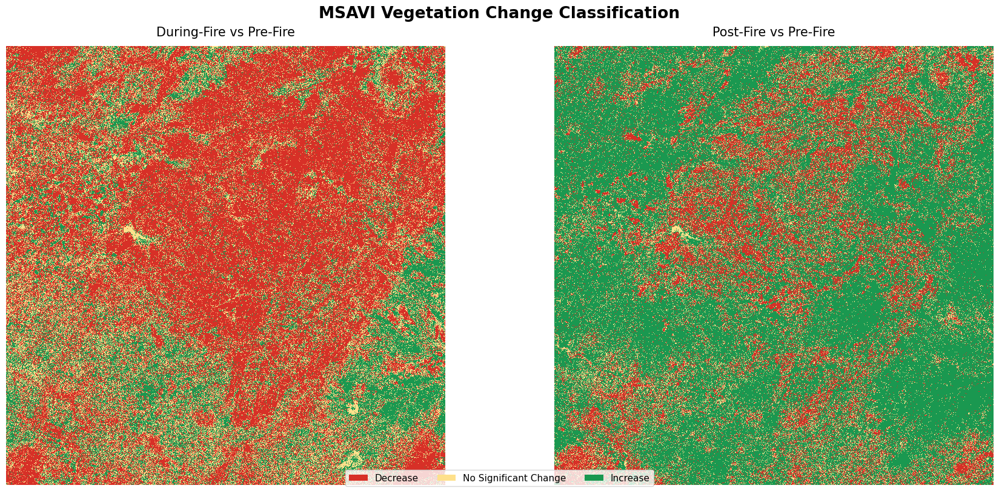

In [61]:

# ============================================================
# CELL 18: MSAVI CHANGE CATEGORY MAPS
# ============================================================

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Classify change:
# 0 = Decrease
# 1 = No significant change
# 2 = Increase

def classify_msavi_change(change_map, mask):

    classified = np.full(
        change_map.shape,
        255,
        dtype=np.uint8
    )

    classified[mask & (change_map < -threshold)] = 0

    classified[
        mask &
        (change_map >= -threshold) &
        (change_map <= threshold)
    ] = 1

    classified[mask & (change_map > threshold)] = 2

    return classified


during_class = classify_msavi_change(
    during_change, common_mask
)

post_class = classify_msavi_change(
    post_change, common_mask
)

cmap = ListedColormap([
    "#D73027",  # Decrease
    "#FEE08B",  # No significant change
    "#1A9850"   # Increase
])

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    constrained_layout=True
)

for ax, data, title in zip(
    axes,
    [during_class, post_class],
    ["During-Fire vs Pre-Fire", "Post-Fire vs Pre-Fire"]
):

    masked_data = np.ma.masked_equal(data, 255)

    ax.imshow(
        masked_data,
        cmap=cmap,
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=15, pad=12)
    ax.axis("off")

legend_items = [
    Patch(facecolor="#D73027", label="Decrease"),
    Patch(facecolor="#FEE08B", label="No Significant Change"),
    Patch(facecolor="#1A9850", label="Increase")
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    fontsize=11,
    frameon=True
)

fig.suptitle(
    "MSAVI Vegetation Change Classification",
    fontsize=19,
    fontweight="bold"
)

plt.show()


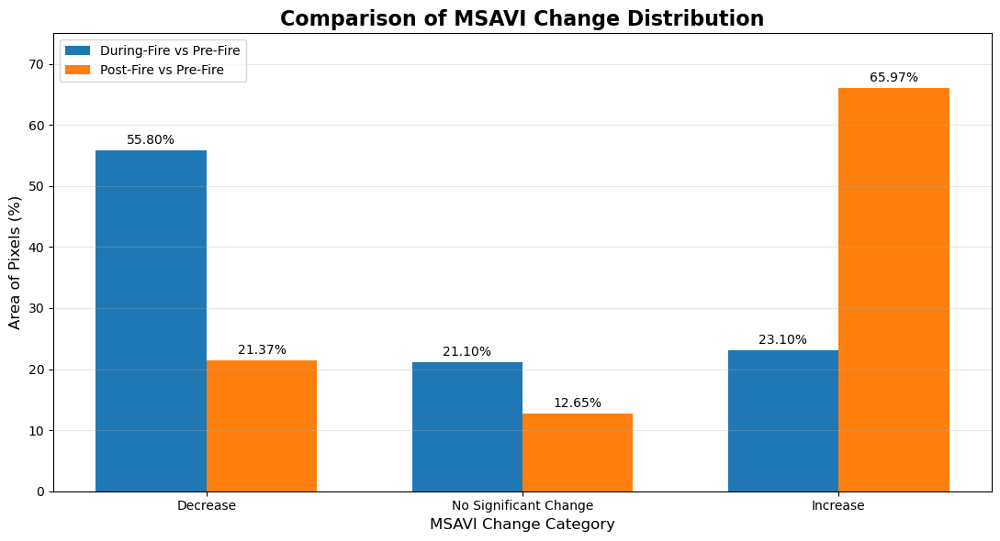

In [62]:

# ============================================================
# CELL 19: MSAVI CHANGE COMPARISON CHART
# ============================================================

categories = [
    "Decrease",
    "No Significant Change",
    "Increase"
]

during_percentages = [
    during_stats[c] / np.sum(list(during_stats.values())) * 100
    for c in categories
]

post_percentages = [
    post_stats[c] / np.sum(list(post_stats.values())) * 100
    for c in categories
]

x = np.arange(len(categories))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width/2,
    during_percentages,
    width,
    label="During-Fire vs Pre-Fire"
)

ax.bar(
    x + width/2,
    post_percentages,
    width,
    label="Post-Fire vs Pre-Fire"
)

ax.set_ylabel("Area of Pixels (%)", fontsize=12)
ax.set_xlabel("MSAVI Change Category", fontsize=12)
ax.set_title(
    "Comparison of MSAVI Change Distribution",
    fontsize=16,
    fontweight="bold"
)

ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.set_ylim(0, 75)
ax.legend()
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.tight_layout()
plt.show()


In [63]:

import os
import pandas as pd
from pathlib import Path
from IPython.display import display

# =====================================================
# 1. SET YOUR PROJECT DIRECTORY
# =====================================================

PROJECT_DIR = Path.cwd()

# If the notebook is not running from Similipal_Project,
# specify the complete path manually:
# PROJECT_DIR = Path("/Users/your_username/path/Similipal_Project")

print("=" * 80)
print("SIMILIPAL FOREST FIRE PROJECT - FILE INVENTORY")
print("=" * 80)
print("Project Root:", PROJECT_DIR.resolve())

# =====================================================
# 2. SCAN ALL IMAGE AND RASTER FILES
# =====================================================

extensions = {
    ".tif", ".tiff", ".png", ".jpg", ".jpeg",
    ".bmp", ".gif", ".webp"
}

records = []

for root, dirs, files in os.walk(PROJECT_DIR):

    dirs[:] = [
        d for d in dirs
        if d not in {".git", ".ipynb_checkpoints", "__pycache__"}
    ]

    for filename in files:

        file_path = Path(root) / filename

        if file_path.suffix.lower() not in extensions:
            continue

        record = {
            "File Name": filename,
            "Type": file_path.suffix.lower(),
            "Folder": str(file_path.parent.relative_to(PROJECT_DIR)),
            "Full Path": str(file_path.resolve()),
            "Size (MB)": round(file_path.stat().st_size / (1024**2), 2),
            "Width": None,
            "Height": None,
            "Bands": None,
            "CRS": None,
            "Data Type": None
        }

        # GeoTIFF metadata
        if file_path.suffix.lower() in {".tif", ".tiff"}:
            try:
                import rasterio

                with rasterio.open(file_path) as src:
                    record["Width"] = src.width
                    record["Height"] = src.height
                    record["Bands"] = src.count
                    record["CRS"] = str(src.crs)
                    record["Data Type"] = str(src.dtypes)

            except Exception as e:
                record["Data Type"] = f"Error: {e}"

        # Normal image metadata
        else:
            try:
                from PIL import Image

                with Image.open(file_path) as img:
                    record["Width"], record["Height"] = img.size

            except Exception as e:
                record["Data Type"] = f"Error: {e}"

        records.append(record)

# =====================================================
# 3. DISPLAY COMPLETE INVENTORY
# =====================================================

image_inventory = pd.DataFrame(records)

if not image_inventory.empty:

    image_inventory = image_inventory.sort_values(
        ["Folder", "File Name"]
    ).reset_index(drop=True)

    print("\nTOTAL IMAGE / RASTER FILES:", len(image_inventory))

    display(image_inventory)

    # =================================================
    # 4. DISPLAY IMPORTANT FIRE PROJECT FILES
    # =================================================

    keywords = [
        "pre", "during", "post", "ndvi", "evi",
        "ndmi", "bri", "msavi", "lst", "evs",
        "vulnerability", "severity", "change",
        "fire", "impact", "burn"
    ]

    important_files = image_inventory[
        image_inventory["File Name"].str.lower().apply(
            lambda name: any(word in name for word in keywords)
        )
    ]

    print("\nIMPORTANT FIRE ANALYSIS FILES:")
    display(important_files)

    # =================================================
    # 5. FILE TYPE SUMMARY
    # =================================================

    print("\nFILE TYPE SUMMARY:")
    display(
        image_inventory.groupby("Type")
        .size()
        .reset_index(name="Number of Files")
    )

    # =================================================
    # 6. SAVE INVENTORY AS CSV
    # =================================================

    csv_path = PROJECT_DIR / "project_image_inventory.csv"
    image_inventory.to_csv(csv_path, index=False)

    print("\nINVENTORY CSV SAVED:")
    print(csv_path.resolve())

else:
    print("\nNo image files found. Check your PROJECT_DIR.")

# =====================================================
# 7. DISPLAY ALL NOTEBOOK FILES
# =====================================================

print("\nNOTEBOOK FILES IN PROJECT:")

for notebook in PROJECT_DIR.rglob("*.ipynb"):
    if ".ipynb_checkpoints" not in str(notebook):
        print(notebook.resolve())


SIMILIPAL FOREST FIRE PROJECT - FILE INVENTORY
Project Root: /Users/pragya/Documents/Similipal_Project

TOTAL IMAGE / RASTER FILES: 54


,File Name,Type,Folder,Full Path,Size (MB),Width,Height,Bands,CRS,Data Type
0,cloud_mask_result.png,.png,.,/Users/pragya/Documents/Similipal_Project/clou...,7.47,4439,1533,NaN,None,None
1,dBRI_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dBRI...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
2,dBRI_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dBRI...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
3,dLST_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dLST...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
4,dLST_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dLST...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
5,dNDVI_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dNDV...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
6,dNDVI_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dNDV...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
7,diffrences.png,.png,.,/Users/pragya/Documents/Similipal_Project/diff...,0.22,1660,984,NaN,None,None
8,lst2.png,.png,.,/Users/pragya/Documents/Similipal_Project/lst2...,0.26,512,482,NaN,None,None
9,newarchitecturedia.jpeg,.jpeg,.,/Users/pragya/Documents/Similipal_Project/newa...,0.09,1167,997,NaN,None,None



IMPORTANT FIRE ANALYSIS FILES:


,File Name,Type,Folder,Full Path,Size (MB),Width,Height,Bands,CRS,Data Type
1,dBRI_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dBRI...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
2,dBRI_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dBRI...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
3,dLST_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dLST...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
4,dLST_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dLST...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
5,dNDVI_During.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dNDV...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
6,dNDVI_Post.tif,.tif,.,/Users/pragya/Documents/Similipal_Project/dNDV...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
8,lst2.png,.png,.,/Users/pragya/Documents/Similipal_Project/lst2...,0.26,512,482,NaN,None,None
10,BRI_During-Fire.tif,.tif,Fire_Project,/Users/pragya/Documents/Similipal_Project/Fire...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
11,BRI_Post-Fire.tif,.tif,Fire_Project,/Users/pragya/Documents/Similipal_Project/Fire...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"
12,BRI_Pre-Fire.tif,.tif,Fire_Project,/Users/pragya/Documents/Similipal_Project/Fire...,231.86,7793,7798,1.0,EPSG:4326,"('float32',)"



FILE TYPE SUMMARY:


,Type,Number of Files
0,.jpeg,2
1,.png,8
2,.tif,44



INVENTORY CSV SAVED:
/Users/pragya/Documents/Similipal_Project/project_image_inventory.csv

NOTEBOOK FILES IN PROJECT:
/Users/pragya/Documents/Similipal_Project/fire_analysis.ipynb
/Users/pragya/Documents/Similipal_Project/minor/fire_analysis copy.ipynb
